### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT%20CLFV2.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT%2520CLFV2.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT%20CLFV2.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT%20CLFV2.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "auto"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)

Repository ready: /workspace/Continual-Learning-with-Diffusion-Vision-Transformers (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [2]:
from common import utils


utils.init()

2026-10-12 22:31:45.696628: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Experiment settings


In [3]:
epochs = 100

## CIFAR10 data


In [4]:
from common.dataloader import get_dataset, load_cifar10


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1))
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, drop_remainder=False)

2026-10-12 22:31:57.841921: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1791844317.843544  240178 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 61309 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:87:00.0, compute capability: 8.0


## DiT denoiser and classifier


In [5]:
from diffusion.models.transformer.di_t_classifier import DiTClassifier
from diffusion.models.wrapper.diffusion_classifier_v2 import DiffusionClassifierV2


vit = DiTClassifier(
    image_size=32, 
    channels=3, 
    patchify_with_cnn=True, 
    depth=8, 
    dim=128, 
    clf_depth=8, 
    clf_droppath_rate=0.05, 
    classifier_dropout_rate=0.5, 
    force_global_avg_pooling=True
)
model = DiffusionClassifierV2(
    network=vit, 
    use_ema=False, 
    modify_first_t=True, 
    clf_loss_coef=0.00215, 
    clf_acc_coef=1.0, 
    clf_distil_acc_coef=0.0, 
    clf_train_class_input_type="null_class_only", 
    clf_train_noisified_max_timesteps=64, 
    clf_test_noisified_max_timesteps=0, 
    train_noisified_max_timesteps=1000, 
    mask_by_nulls=False, 
    test_steps=100, 
    test_cfg_scale=3.0
)

vit.summary()

Model: "di_t_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 128)       │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_7_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_8_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        34,572 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_0_cls_token           │ (None, 1, 128)         │           256 │
│ (SingleTokenLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_feature_aggregator  │ (None, 256, 128)       │             0 │
│ (FeatureHandler)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_1_encoder_block       │ (None, 257, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clf_depth_2_encoder_block       │ (None, 257, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,990,582 (19.04 MB)

 Trainable params: 4,862,486 (18.55 MB)

 Non-trainable params: 128,096 (500.75 KB)

## Optimizer


In [6]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, 
    decay_steps=epochs * len(trainset)
)

model.compile(
    optimizer=optimizers.Adam(lr_schedule), 
    loss="mse"
)

In [7]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator



callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator()
]

## Generator training


Epoch 1/100


2026-10-12 22:32:19.796289: I external/local_xla/xla/service/service.cc:163] XLA service 0x78a6000160f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-12 22:32:19.796320: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2026-10-12 22:32:20.254114: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-12 22:32:22.449952: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-12 22:32:24.094830: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-12 22:32:24.095124: I ext

  2/390 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - noise_loss: 0.9988   

I0000 00:00:1791844367.983505  240581 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


390/390 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - noise_loss: 0.1930

2026-10-12 22:33:14.266696: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-10-12 22:33:20.805495: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 276 bytes spill stores, 276 bytes spill loads

2026-10-12 22:33:31.534978: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-12 22:33:33.998653: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_228', 436 bytes spil

390/390 ━━━━━━━━━━━━━━━━━━━━ 119s 199ms/step - noise_loss: 0.0793 - val_image_loss: 0.1645 - val_loss: 0.0365 - val_noise_loss: 0.0365 - learning_rate: 9.9975e-04
Steps: 100/100


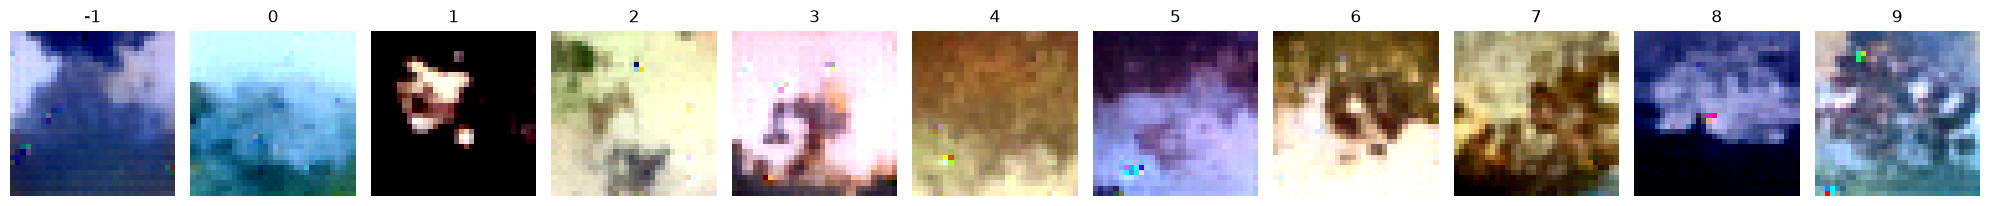

Epoch 2/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0350 - val_image_loss: 0.1238 - val_loss: 0.0349 - val_noise_loss: 0.0349 - learning_rate: 9.9901e-04
Steps: 100/100


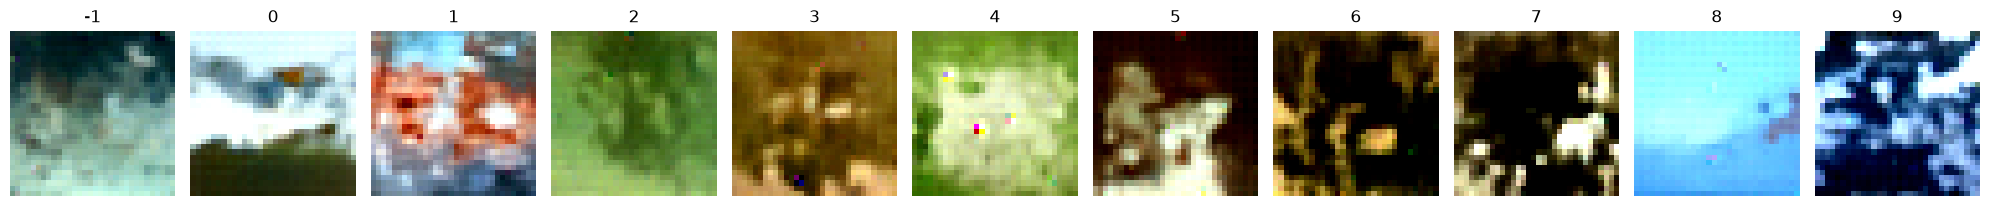

Epoch 3/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0331 - val_image_loss: 0.1049 - val_loss: 0.0334 - val_noise_loss: 0.0334 - learning_rate: 9.9778e-04
Steps: 100/100


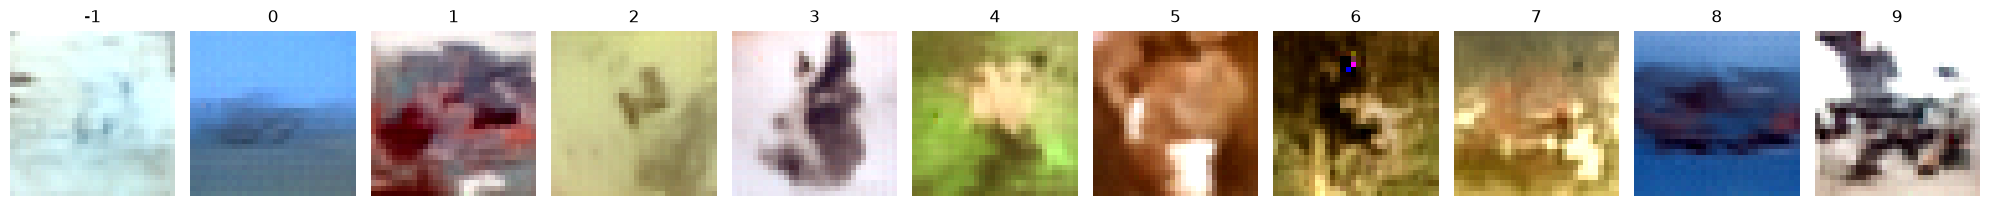

Epoch 4/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0327 - val_image_loss: 0.1013 - val_loss: 0.0329 - val_noise_loss: 0.0329 - learning_rate: 9.9606e-04
Steps: 100/100


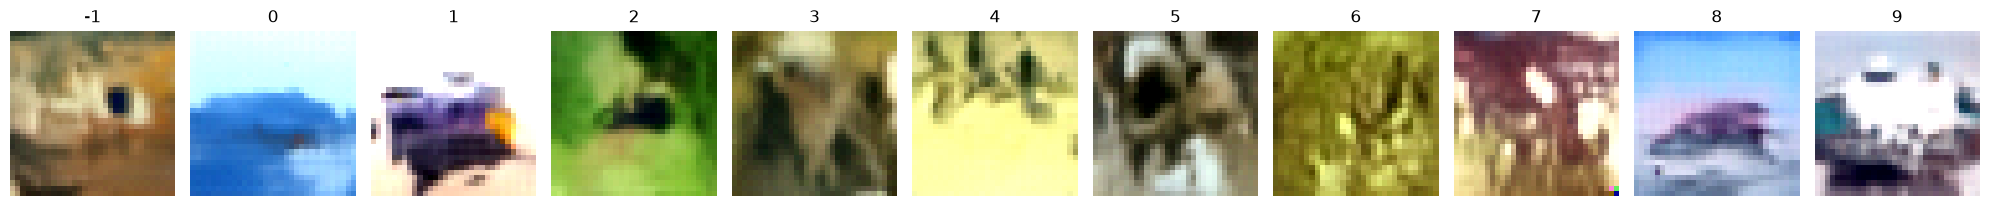

Epoch 5/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0320 - val_image_loss: 0.0881 - val_loss: 0.0328 - val_noise_loss: 0.0328 - learning_rate: 9.9384e-04
Steps: 100/100


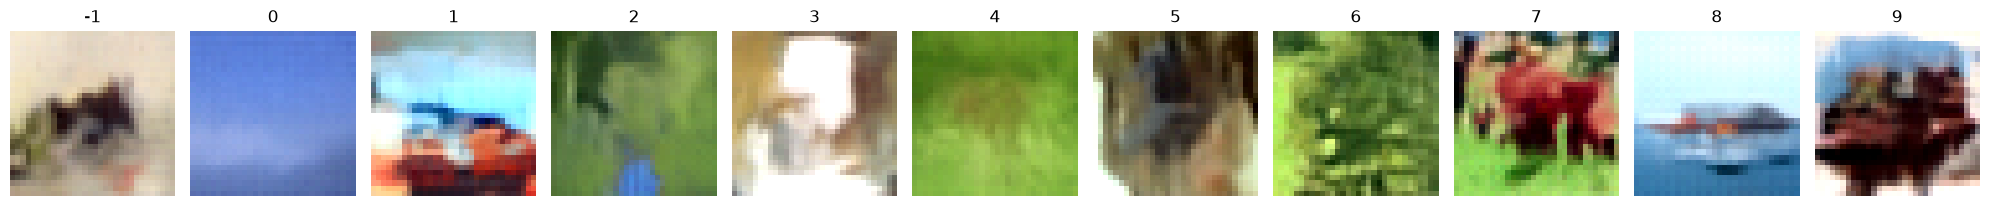

Epoch 6/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0316 - val_image_loss: 0.0908 - val_loss: 0.0323 - val_noise_loss: 0.0323 - learning_rate: 9.9114e-04
Steps: 100/100


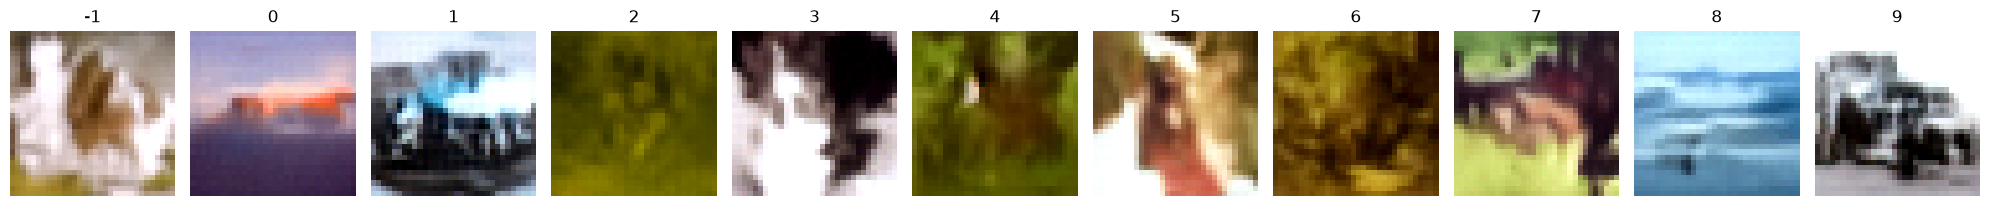

Epoch 7/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - noise_loss: 0.0319 - val_image_loss: 0.0830 - val_loss: 0.0328 - val_noise_loss: 0.0328 - learning_rate: 9.8796e-04
Steps: 100/100


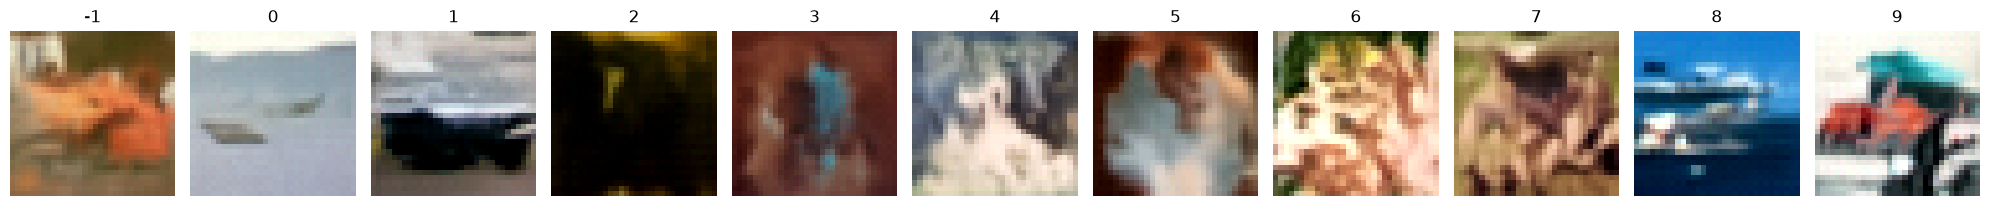

Epoch 8/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0315 - val_image_loss: 0.0866 - val_loss: 0.0329 - val_noise_loss: 0.0329 - learning_rate: 9.8429e-04
Steps: 100/100


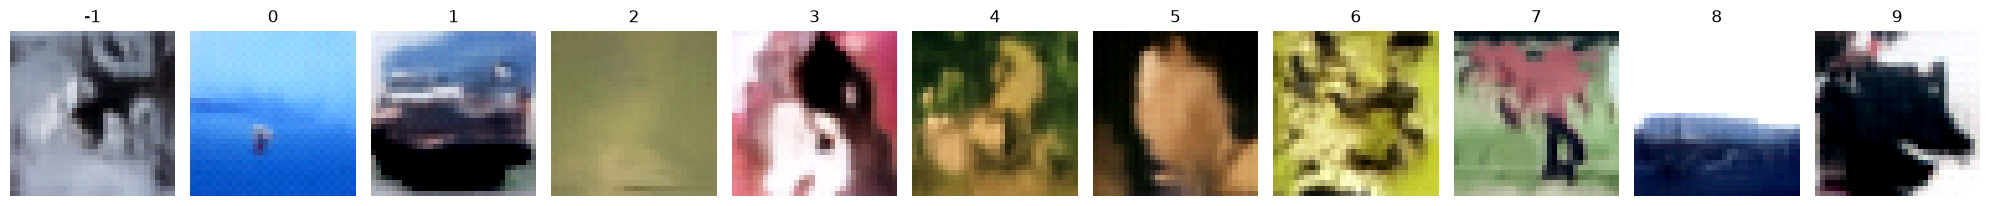

Epoch 9/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0312 - val_image_loss: 0.0863 - val_loss: 0.0321 - val_noise_loss: 0.0321 - learning_rate: 9.8015e-04
Steps: 100/100


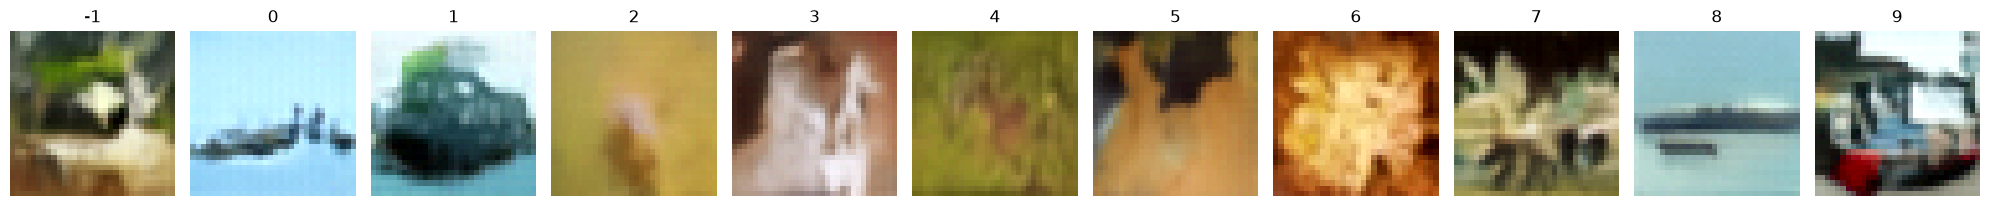

Epoch 10/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0312 - val_image_loss: 0.0876 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 9.7553e-04
Steps: 100/100


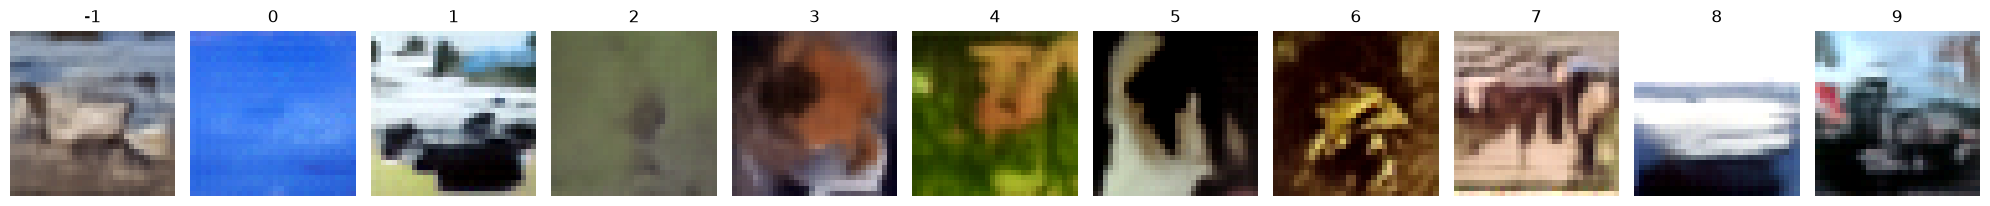

Epoch 11/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0311 - val_image_loss: 0.0841 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 9.7044e-04
Steps: 100/100


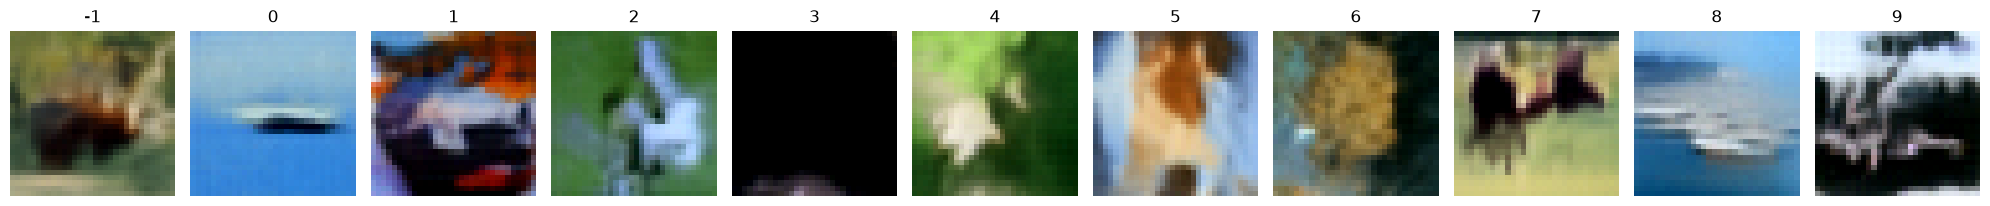

Epoch 12/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0311 - val_image_loss: 0.0849 - val_loss: 0.0316 - val_noise_loss: 0.0316 - learning_rate: 9.6489e-04
Steps: 100/100


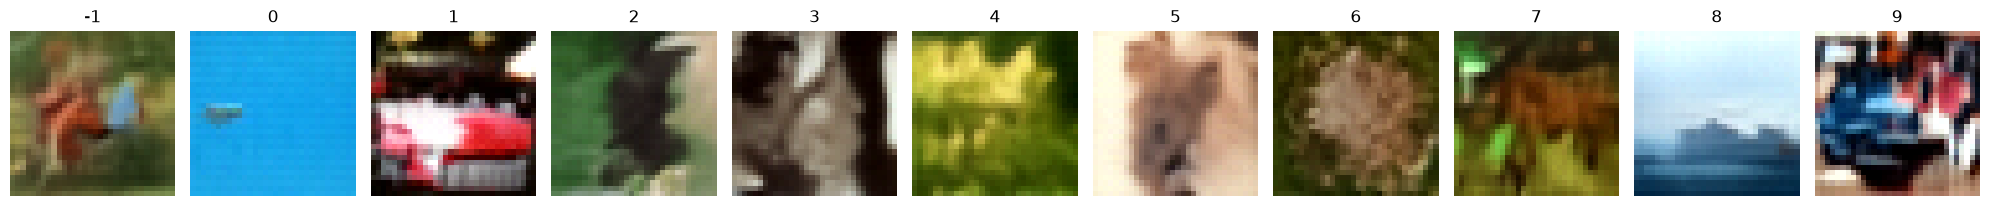

Epoch 13/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0308 - val_image_loss: 0.0837 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 9.5888e-04
Steps: 100/100


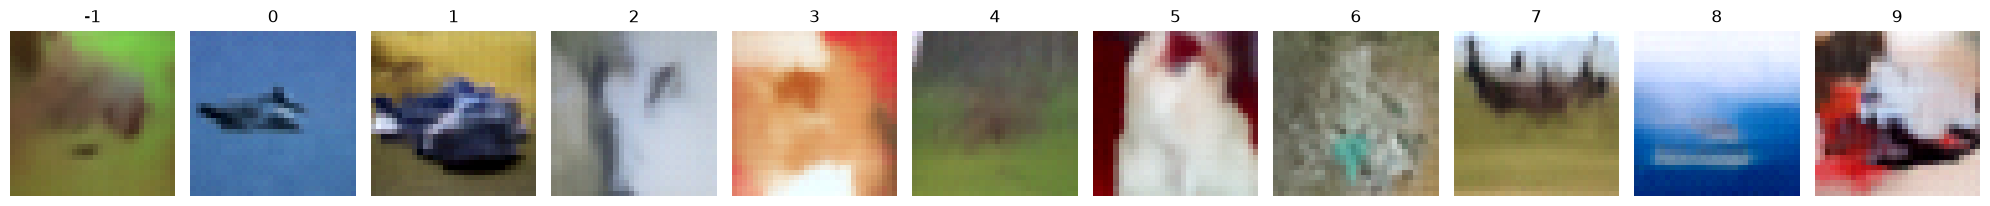

Epoch 14/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0309 - val_image_loss: 0.0817 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 9.5241e-04
Steps: 100/100


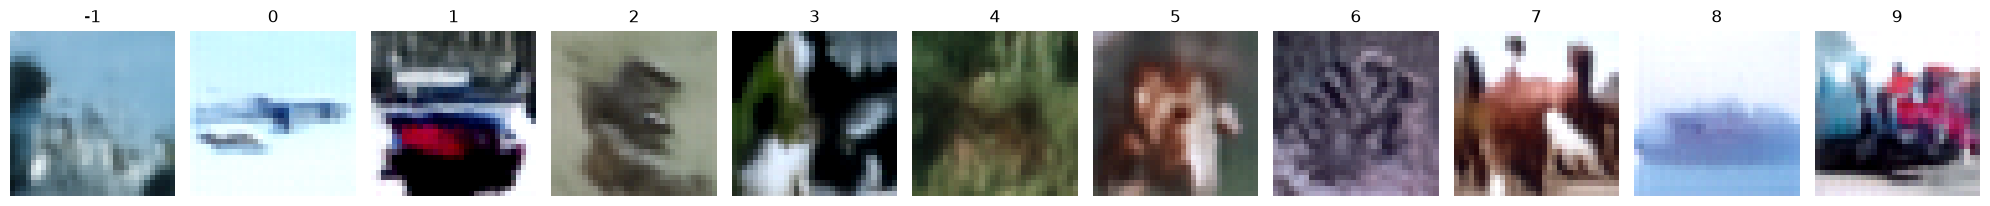

Epoch 15/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0307 - val_image_loss: 0.0793 - val_loss: 0.0320 - val_noise_loss: 0.0320 - learning_rate: 9.4550e-04
Steps: 100/100


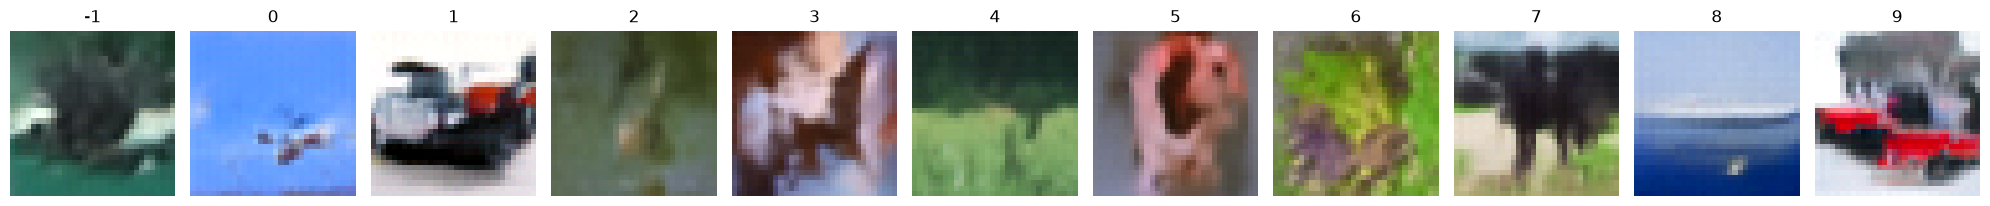

Epoch 16/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0307 - val_image_loss: 0.0812 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 9.3815e-04
Steps: 100/100


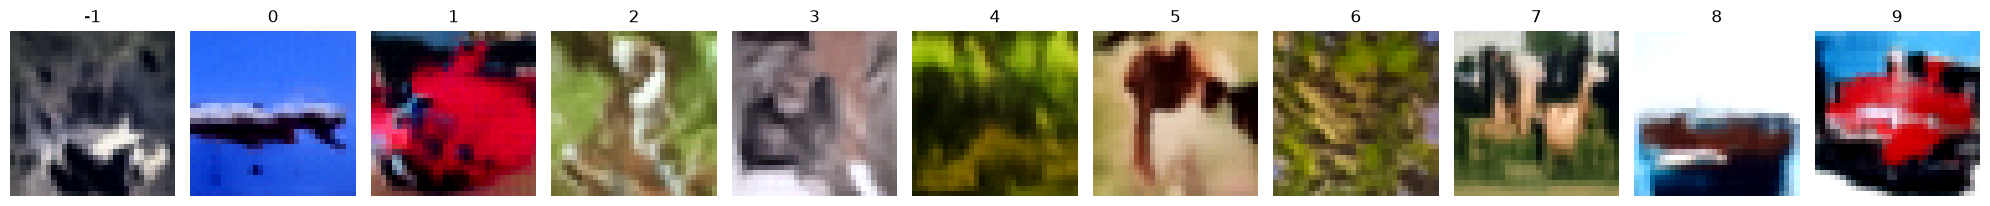

Epoch 17/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0308 - val_image_loss: 0.0813 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 9.3037e-04
Steps: 100/100


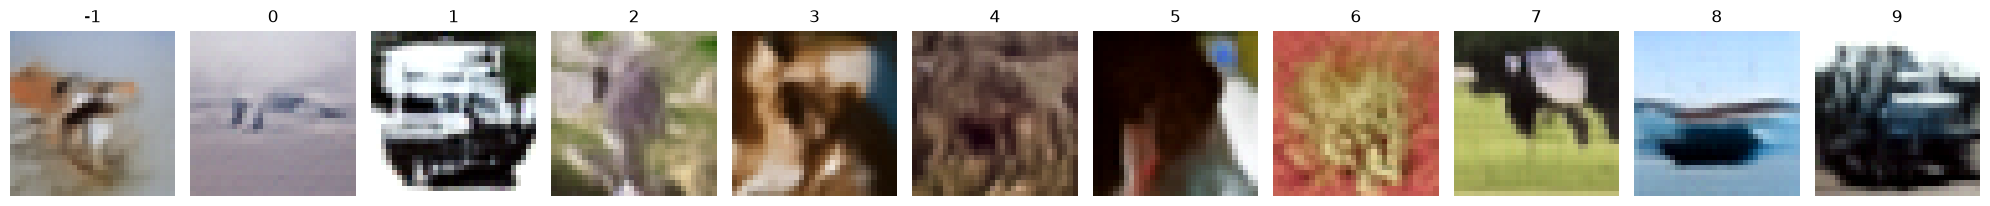

Epoch 18/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0302 - val_image_loss: 0.0783 - val_loss: 0.0319 - val_noise_loss: 0.0319 - learning_rate: 9.2216e-04
Steps: 100/100


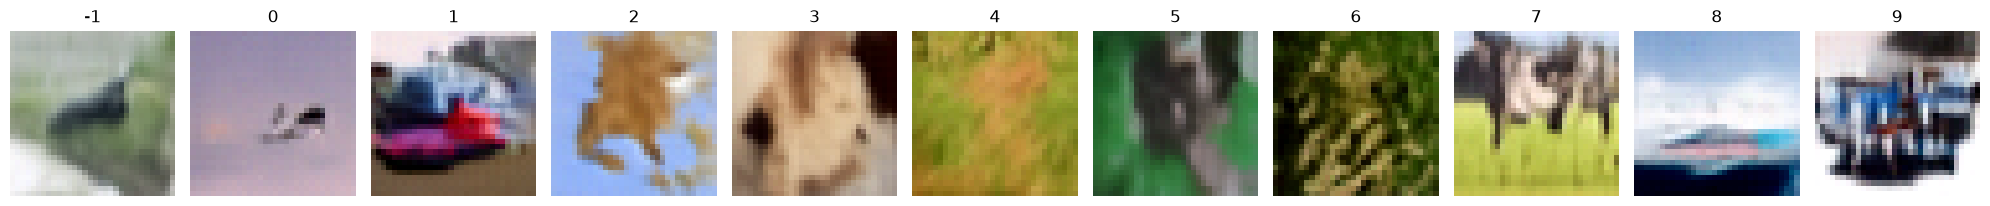

Epoch 19/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0303 - val_image_loss: 0.0831 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 9.1354e-04
Steps: 100/100


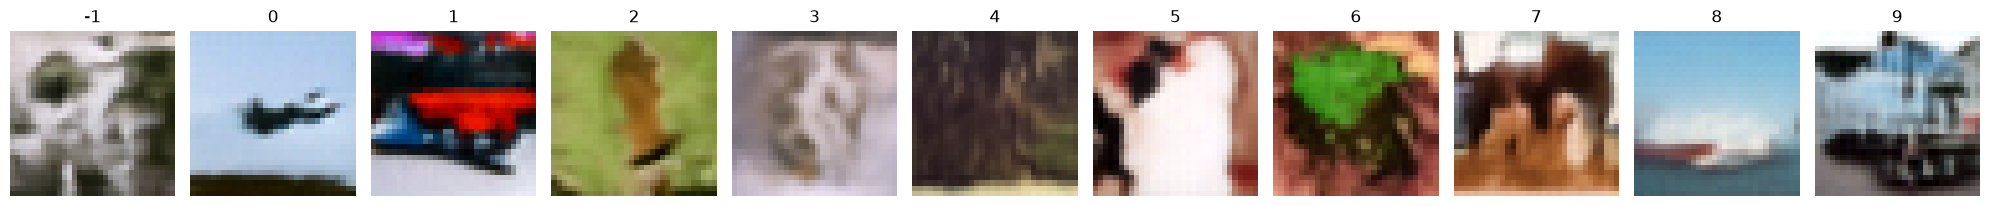

Epoch 20/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0304 - val_image_loss: 0.0777 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 9.0451e-04
Steps: 100/100


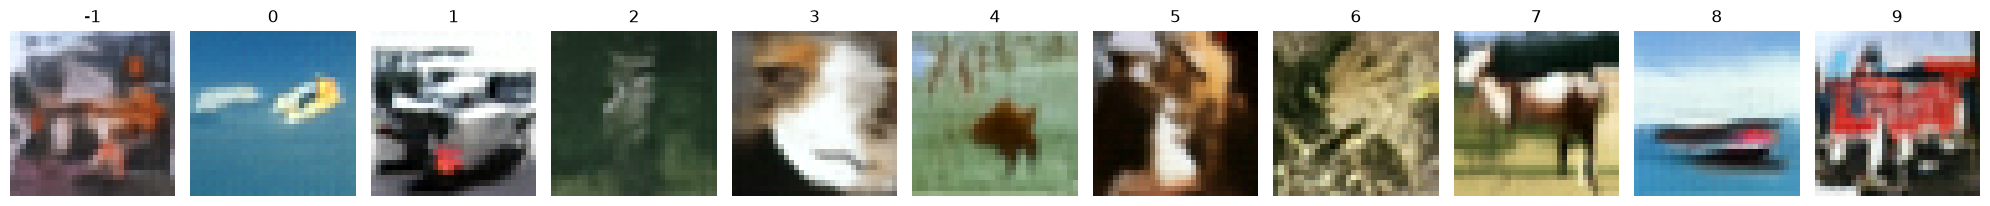

Epoch 21/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0305 - val_image_loss: 0.0765 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 8.9508e-04
Steps: 100/100


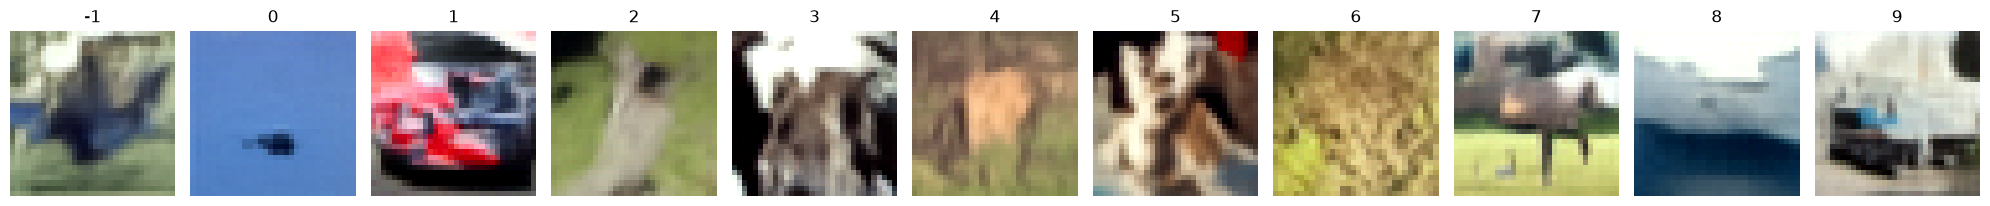

Epoch 22/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0301 - val_image_loss: 0.0783 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 8.8526e-04
Steps: 100/100


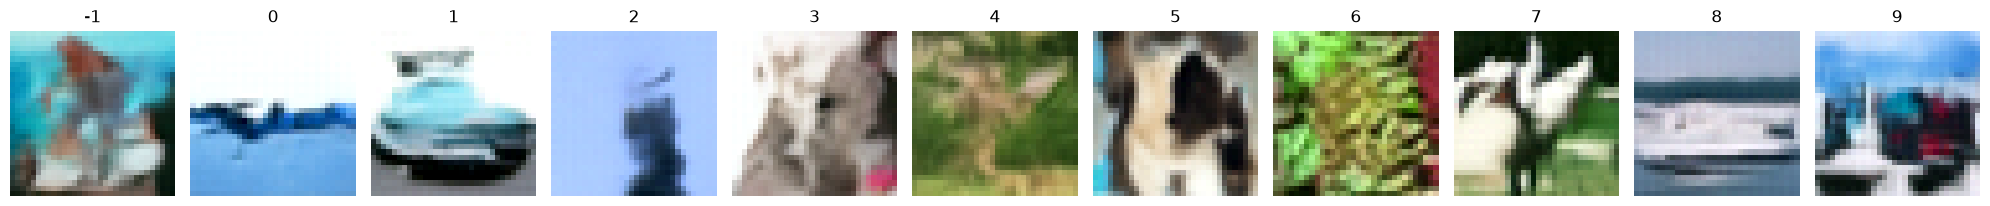

Epoch 23/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0300 - val_image_loss: 0.0788 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 8.7506e-04
Steps: 100/100


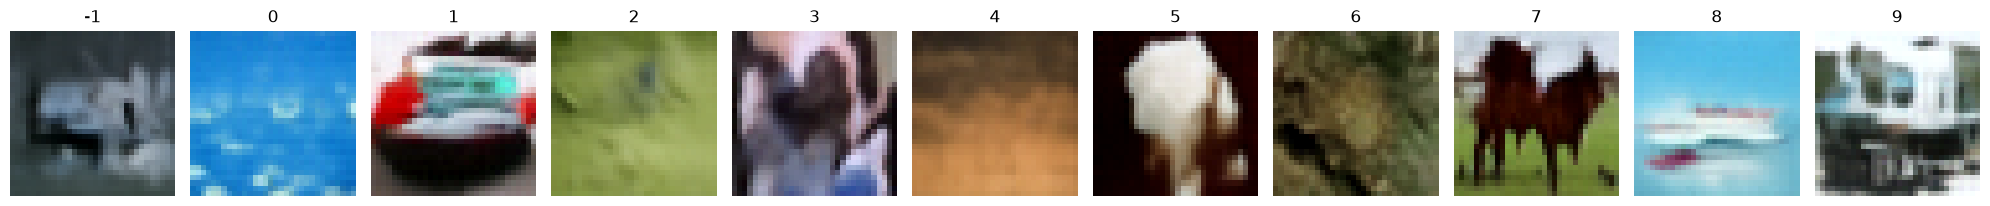

Epoch 24/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0300 - val_image_loss: 0.0778 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 8.6448e-04
Steps: 100/100


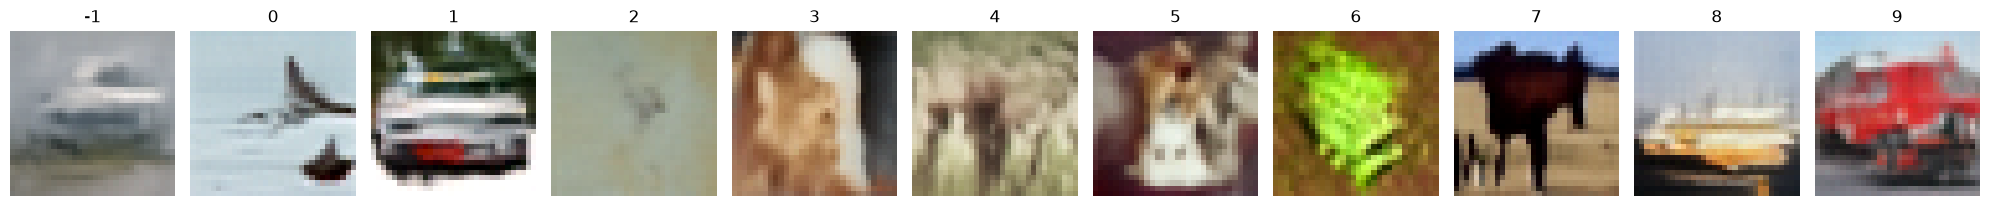

Epoch 25/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0299 - val_image_loss: 0.0786 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 8.5355e-04
Steps: 100/100


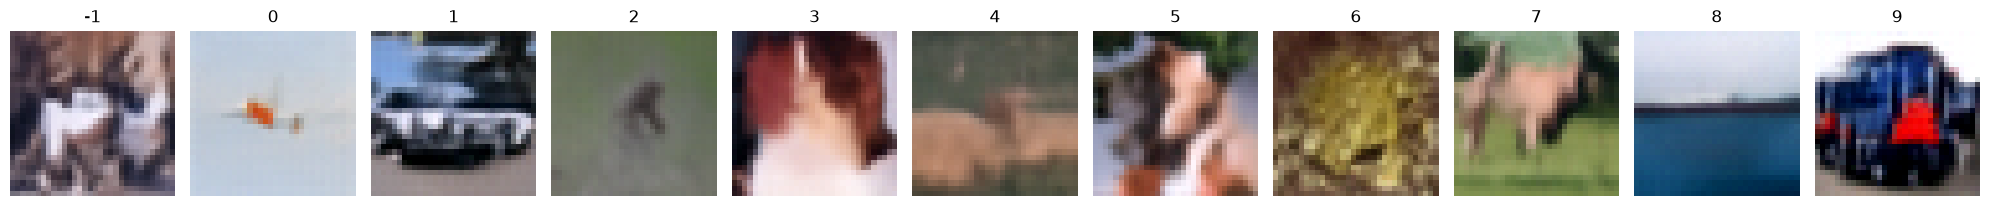

Epoch 26/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0300 - val_image_loss: 0.0751 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 8.4227e-04
Steps: 100/100


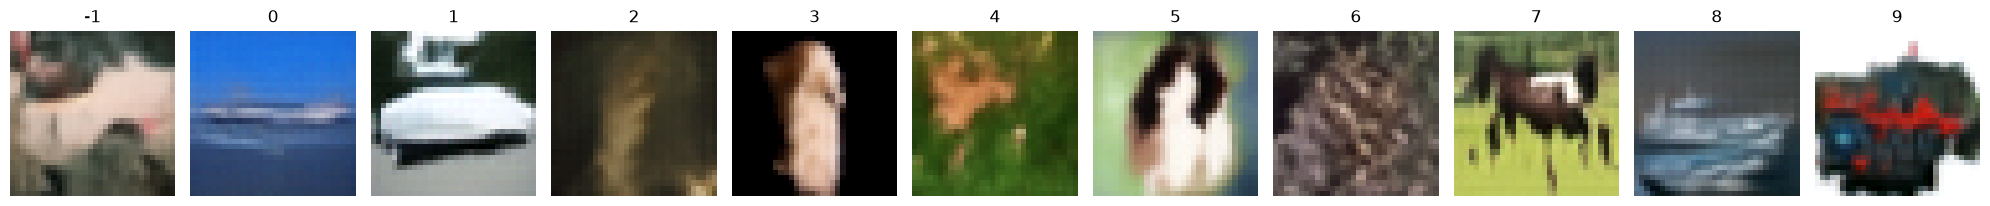

Epoch 27/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0299 - val_image_loss: 0.0788 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 8.3066e-04
Steps: 100/100


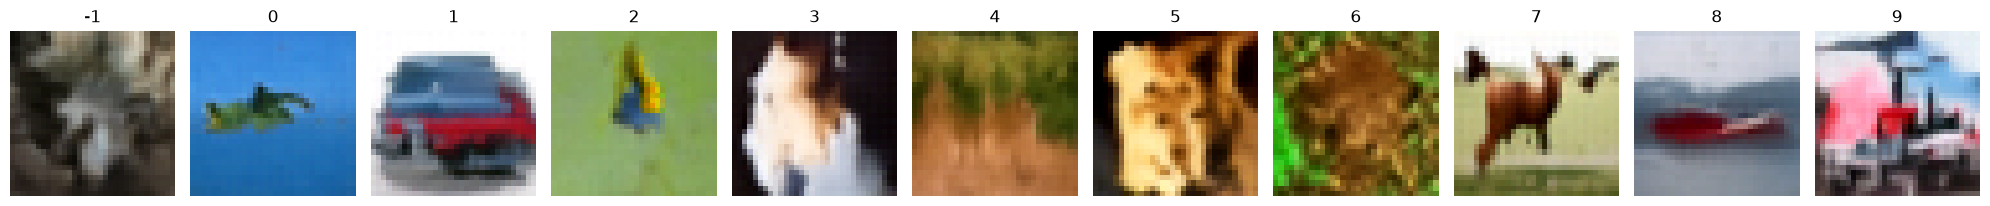

Epoch 28/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0297 - val_image_loss: 0.0756 - val_loss: 0.0310 - val_noise_loss: 0.0310 - learning_rate: 8.1871e-04
Steps: 100/100


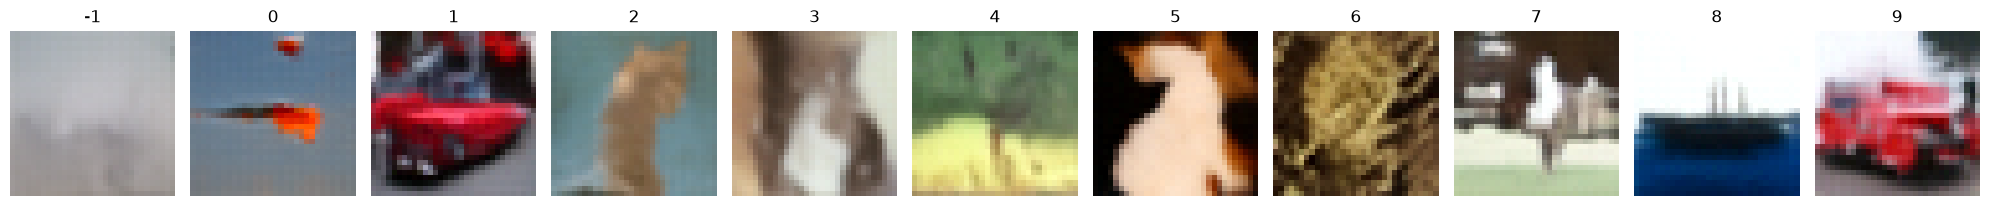

Epoch 29/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0296 - val_image_loss: 0.0793 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 8.0645e-04
Steps: 100/100


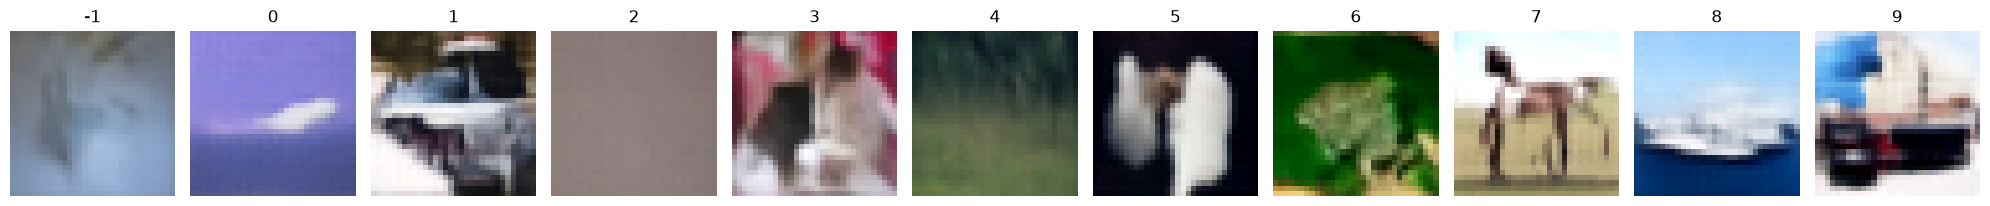

Epoch 30/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0298 - val_image_loss: 0.0759 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 7.9389e-04
Steps: 100/100


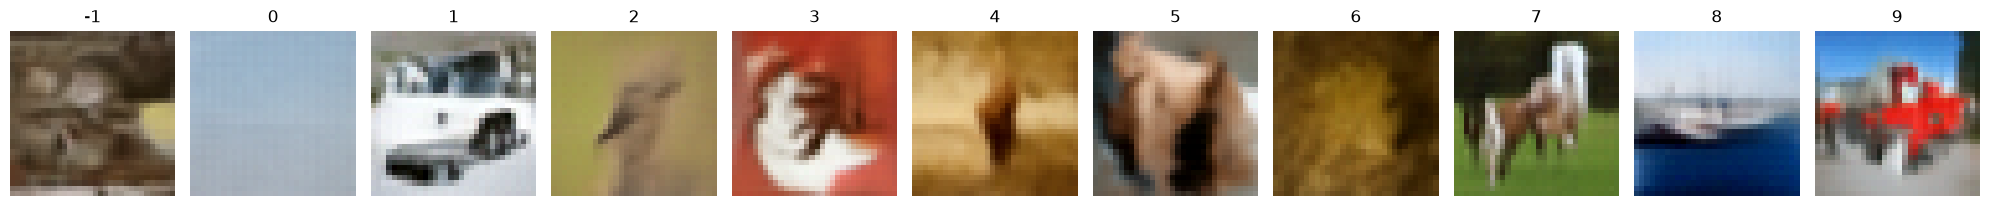

Epoch 31/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0300 - val_image_loss: 0.0764 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 7.8104e-04
Steps: 100/100


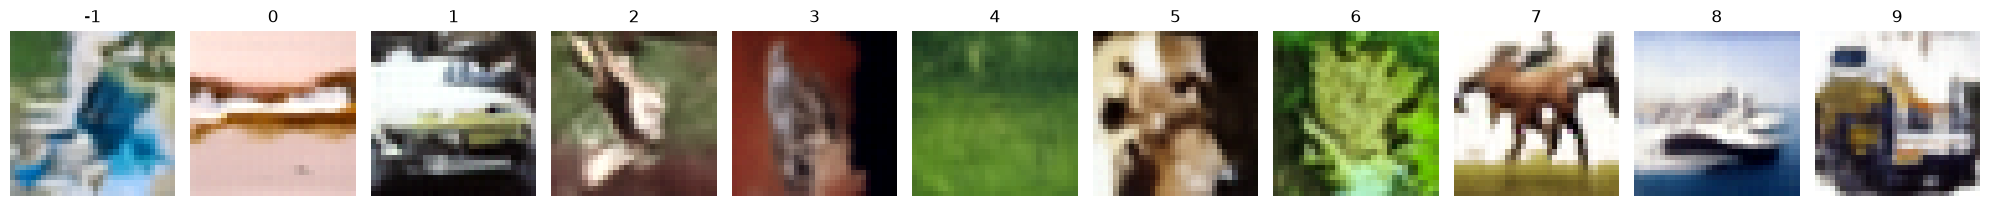

Epoch 32/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0299 - val_image_loss: 0.0779 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 7.6791e-04
Steps: 100/100


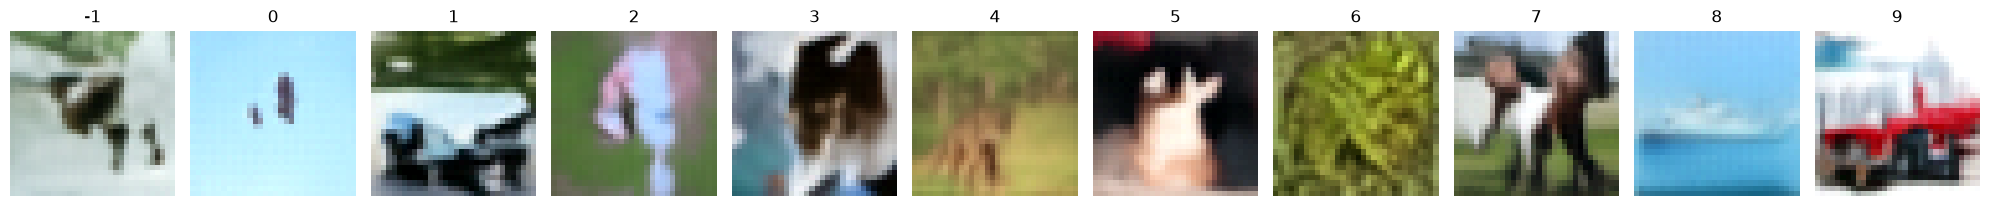

Epoch 33/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0296 - val_image_loss: 0.0774 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 7.5452e-04
Steps: 100/100


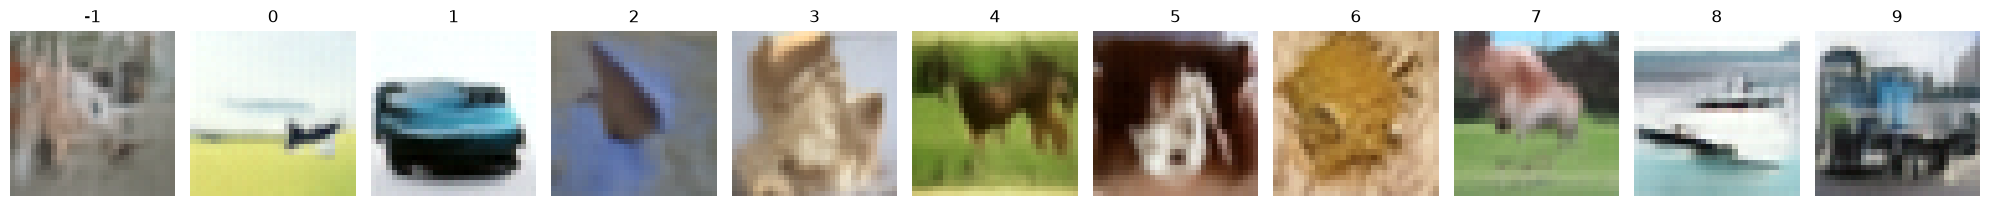

Epoch 34/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0295 - val_image_loss: 0.0802 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 7.4088e-04
Steps: 100/100


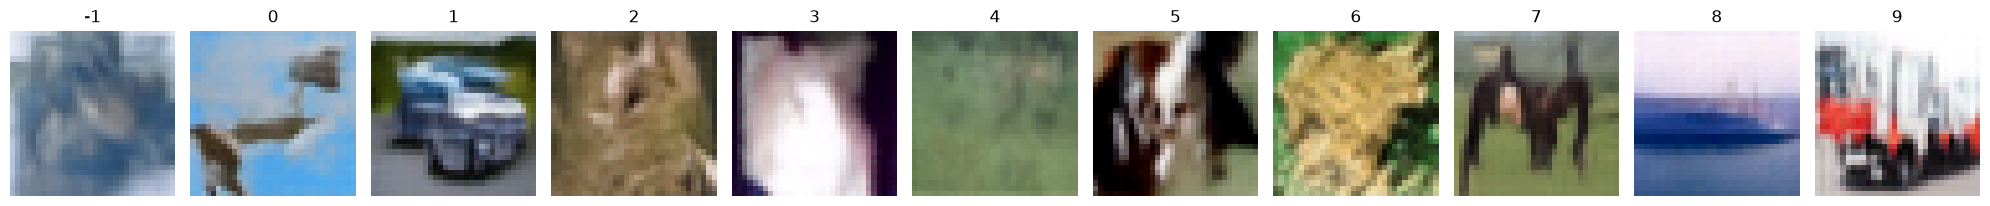

Epoch 35/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0295 - val_image_loss: 0.0758 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 7.2700e-04
Steps: 100/100


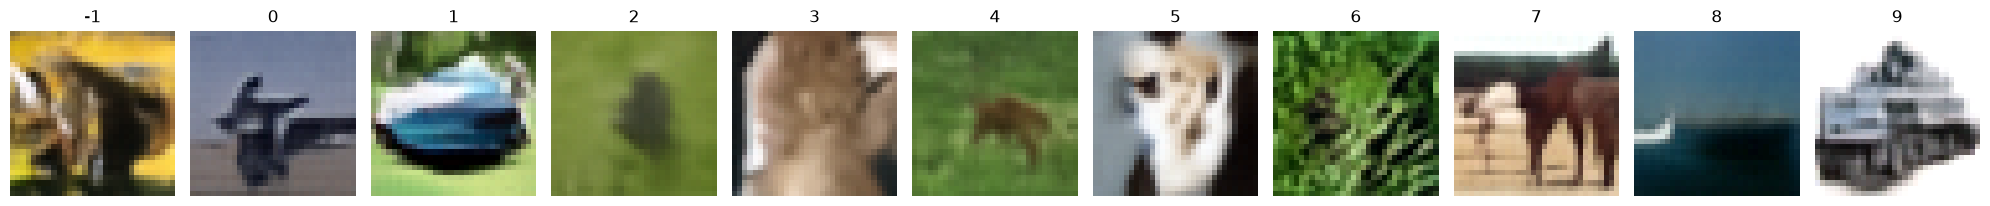

Epoch 36/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0297 - val_image_loss: 0.0743 - val_loss: 0.0322 - val_noise_loss: 0.0322 - learning_rate: 7.1289e-04
Steps: 100/100


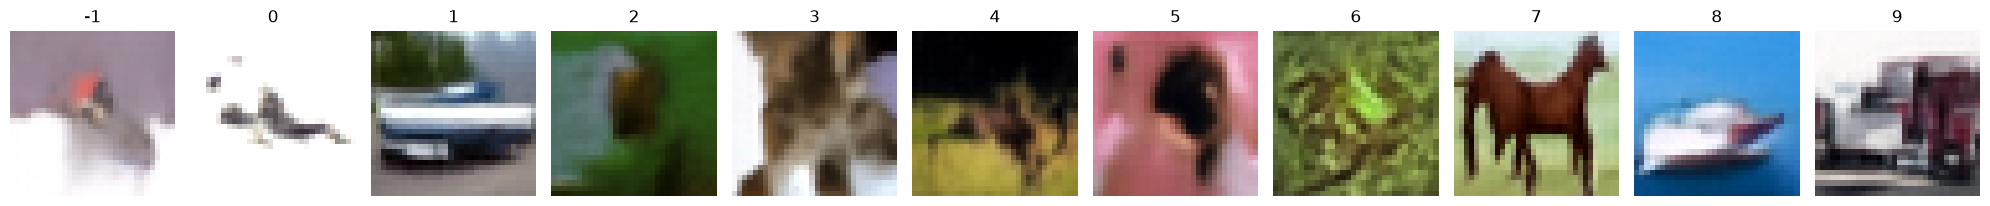

Epoch 37/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0297 - val_image_loss: 0.0732 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 6.9857e-04
Steps: 100/100


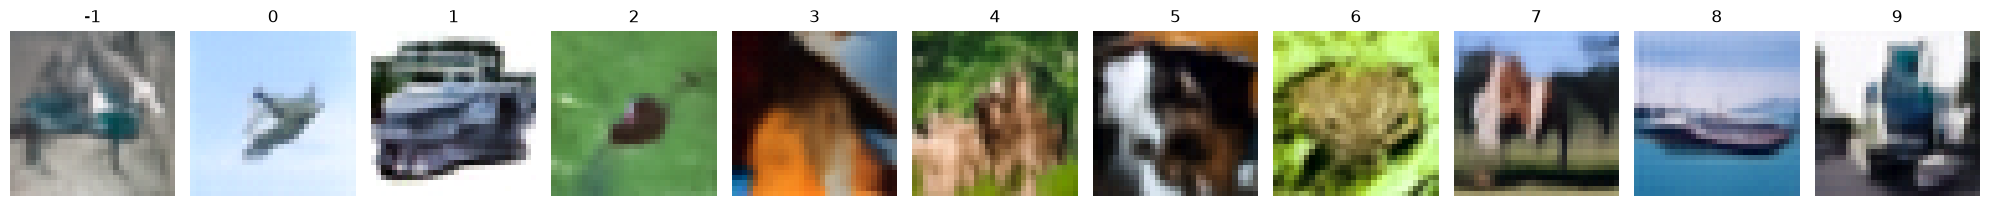

Epoch 38/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0295 - val_image_loss: 0.0770 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 6.8406e-04
Steps: 100/100


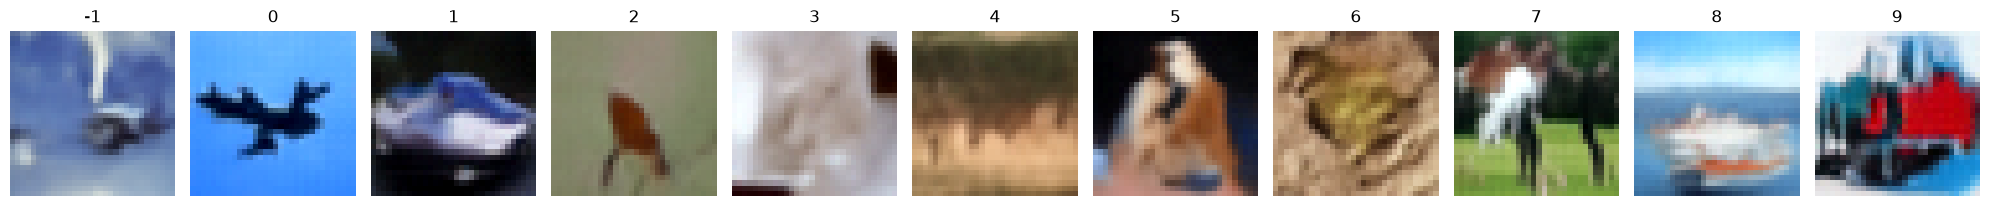

Epoch 39/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0294 - val_image_loss: 0.0792 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 6.6937e-04
Steps: 100/100


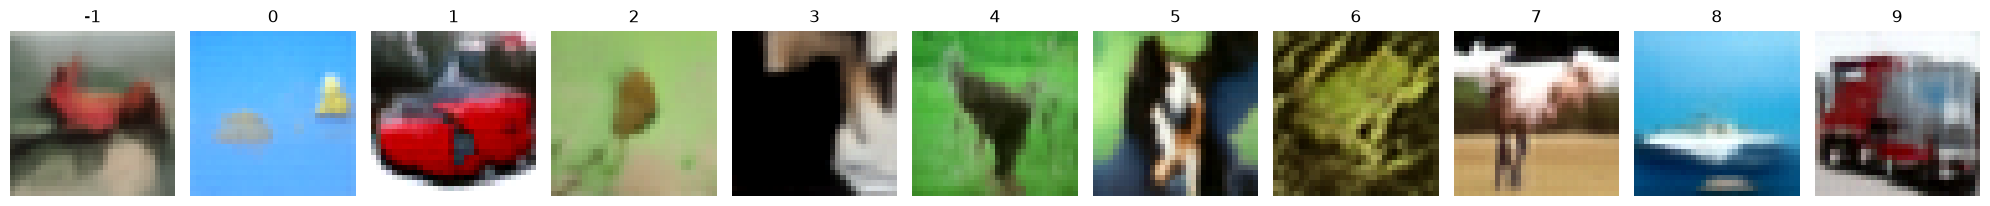

Epoch 40/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0294 - val_image_loss: 0.0746 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 6.5451e-04
Steps: 100/100


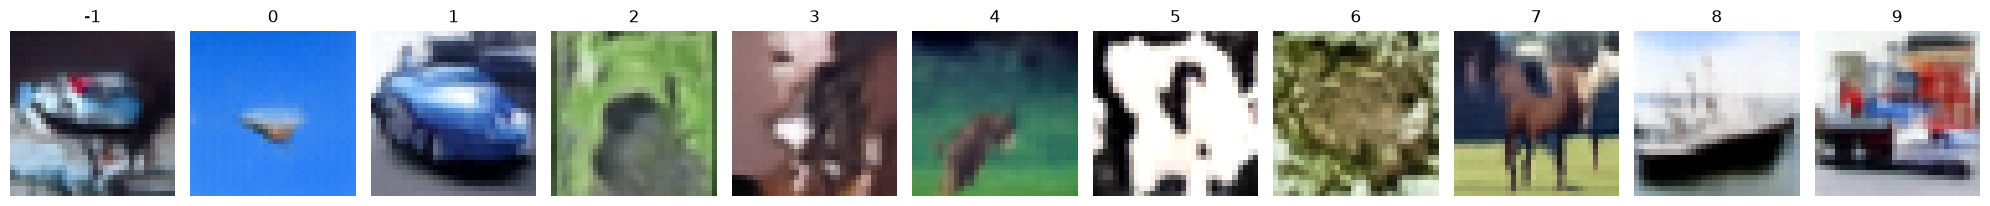

Epoch 41/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0297 - val_image_loss: 0.0771 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 6.3950e-04
Steps: 100/100


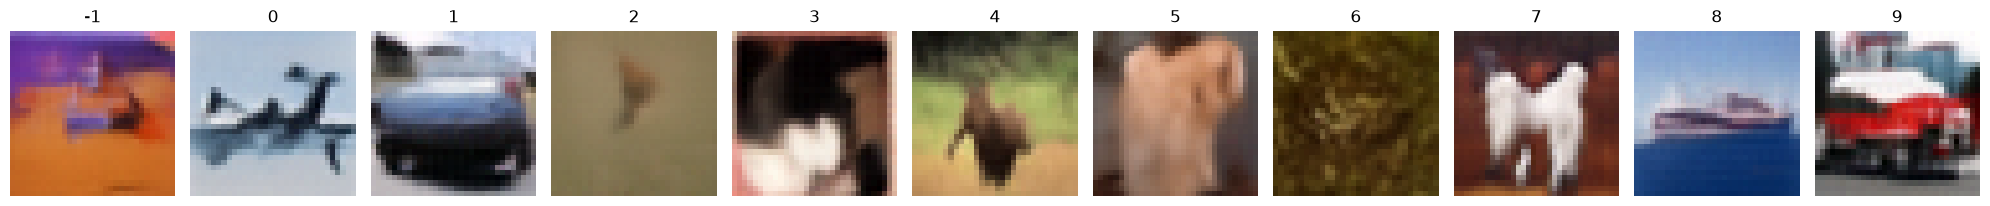

Epoch 42/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 18s 46ms/step - noise_loss: 0.0295 - val_image_loss: 0.0727 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 6.2435e-04
Steps: 100/100


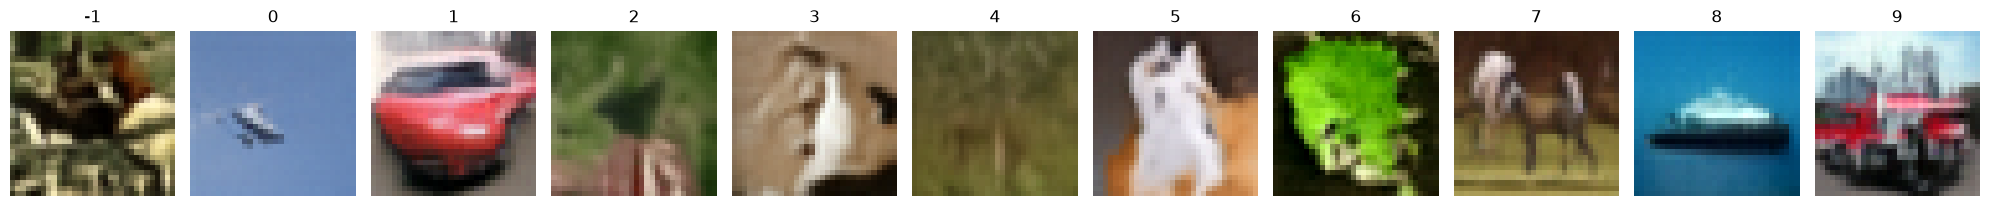

Epoch 43/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0294 - val_image_loss: 0.0748 - val_loss: 0.0316 - val_noise_loss: 0.0316 - learning_rate: 6.0907e-04
Steps: 100/100


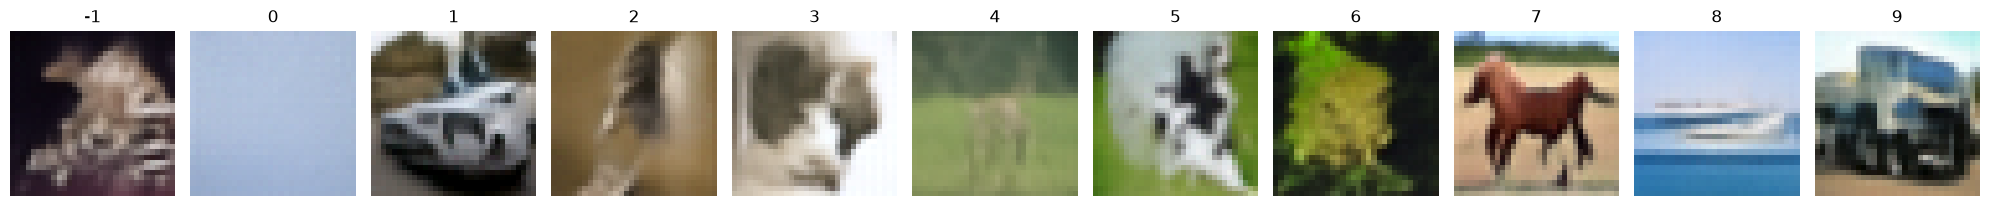

Epoch 44/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0292 - val_image_loss: 0.0731 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 5.9369e-04
Steps: 100/100


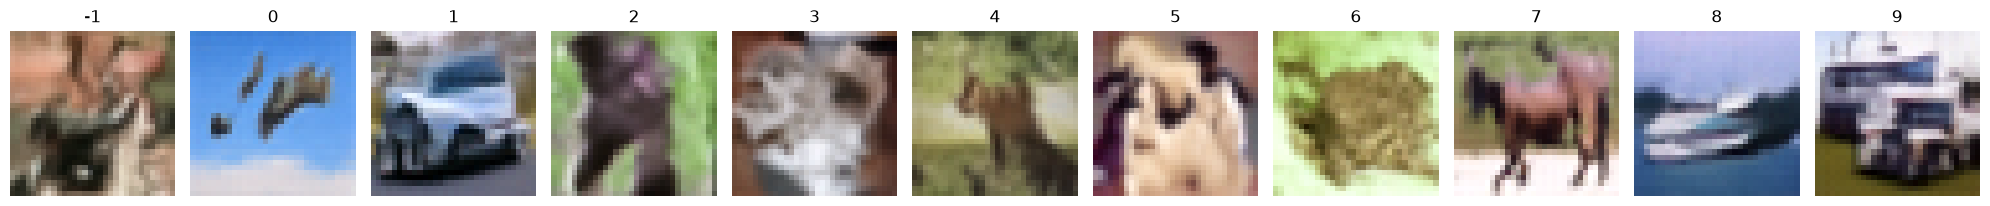

Epoch 45/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0294 - val_image_loss: 0.0738 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 5.7822e-04
Steps: 100/100


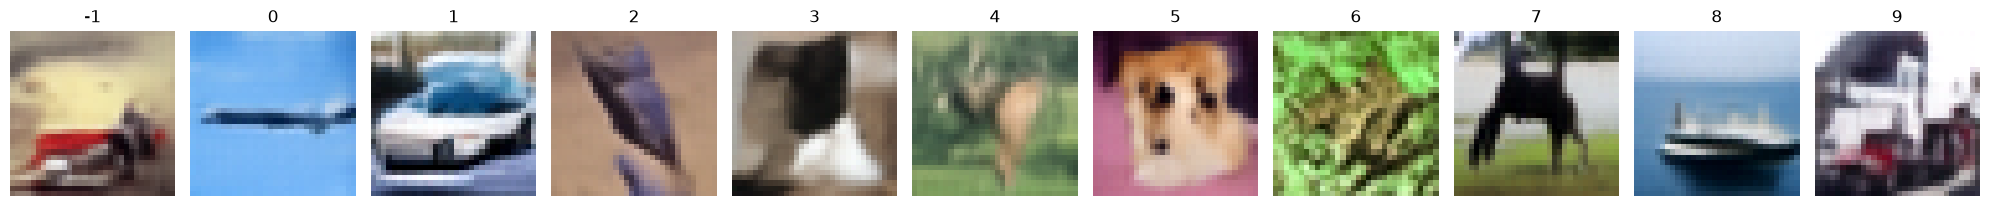

Epoch 46/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0291 - val_image_loss: 0.0757 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 5.6267e-04
Steps: 100/100


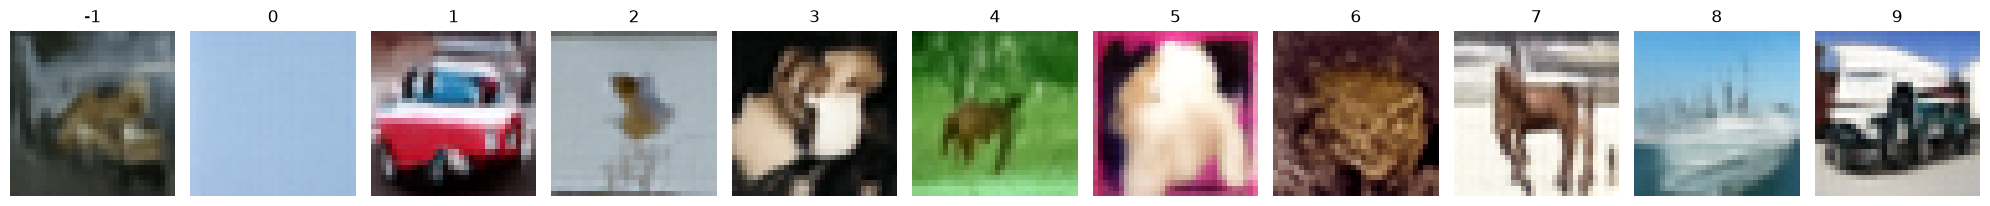

Epoch 47/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0293 - val_image_loss: 0.0743 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 5.4705e-04
Steps: 100/100


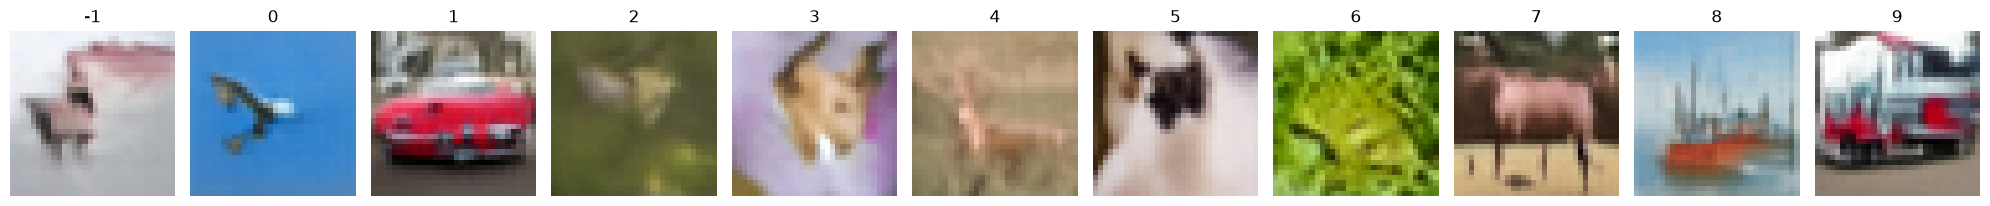

Epoch 48/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0294 - val_image_loss: 0.0748 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 5.3140e-04
Steps: 100/100


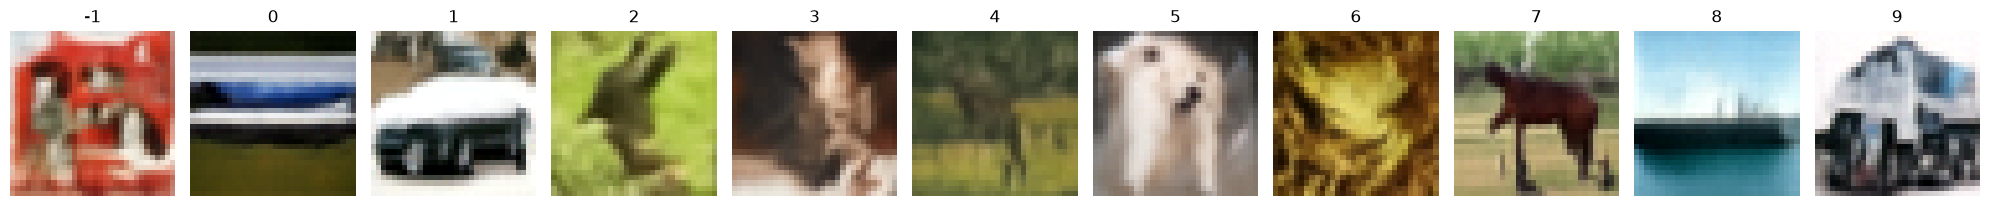

Epoch 49/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - noise_loss: 0.0297 - val_image_loss: 0.0733 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 5.1571e-04
Steps: 100/100


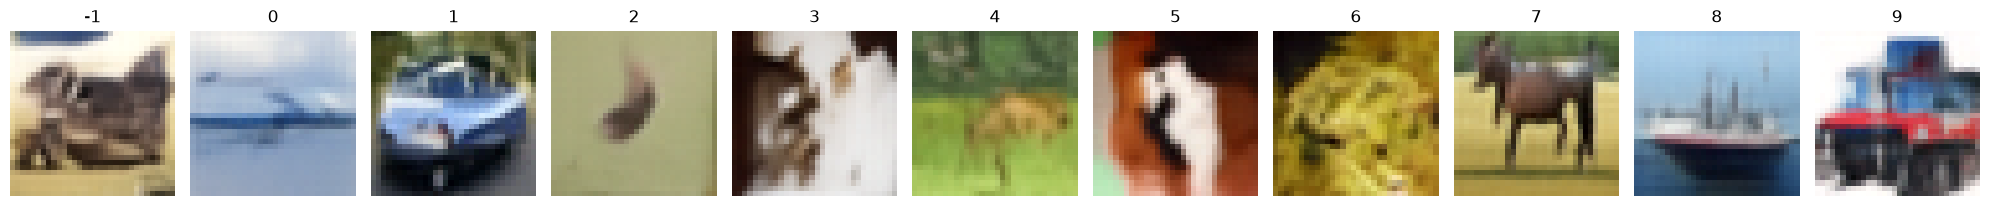

Epoch 50/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0294 - val_image_loss: 0.0761 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 5.0000e-04
Steps: 100/100


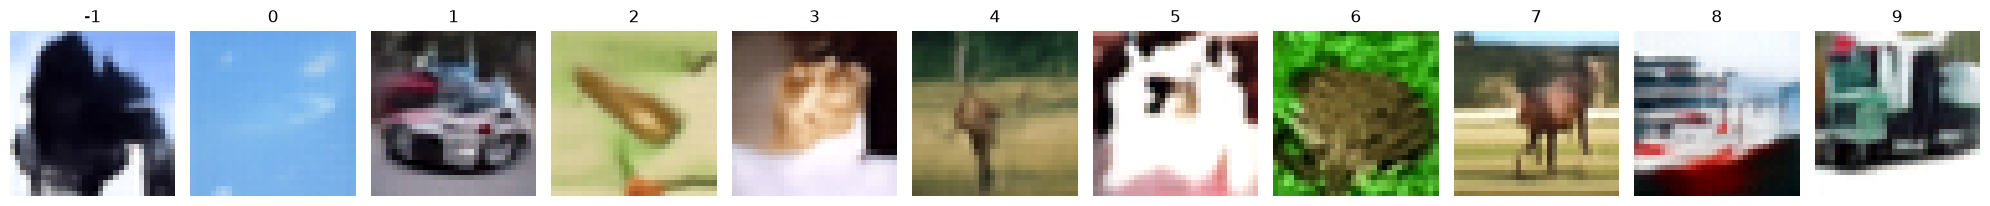

Epoch 51/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0293 - val_image_loss: 0.0737 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 4.8429e-04
Steps: 100/100


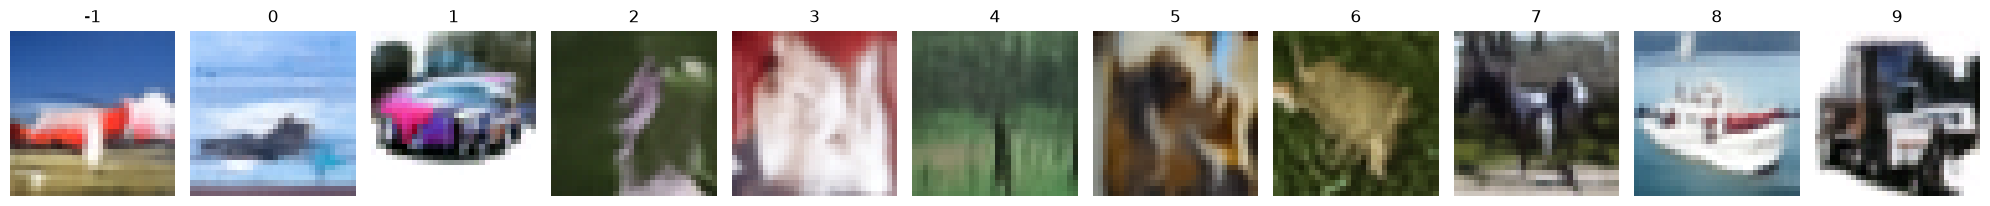

Epoch 52/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0293 - val_image_loss: 0.0744 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 4.6860e-04
Steps: 100/100


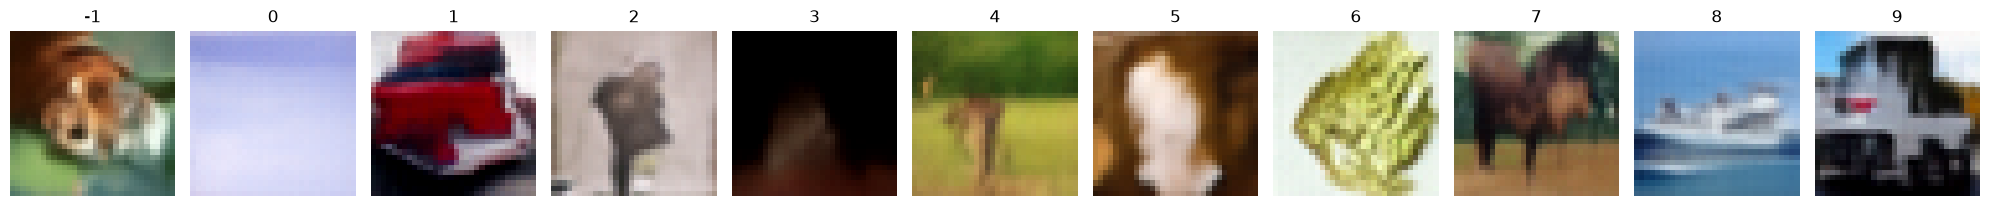

Epoch 53/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0290 - val_image_loss: 0.0723 - val_loss: 0.0305 - val_noise_loss: 0.0305 - learning_rate: 4.5295e-04
Steps: 100/100


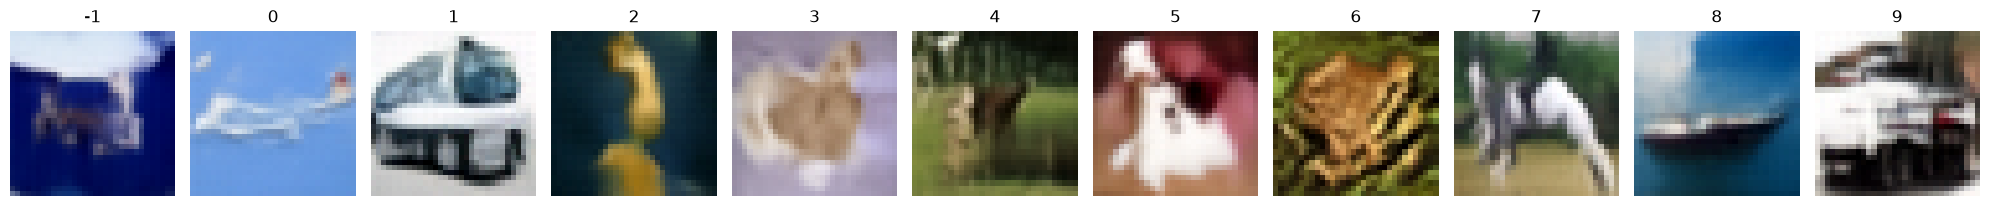

Epoch 54/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0734 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 4.3733e-04
Steps: 100/100


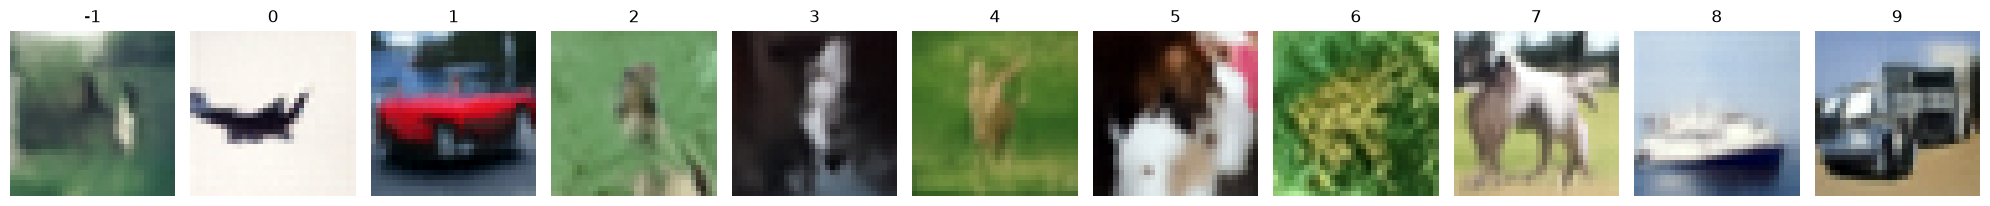

Epoch 55/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0710 - val_loss: 0.0315 - val_noise_loss: 0.0315 - learning_rate: 4.2178e-04
Steps: 100/100


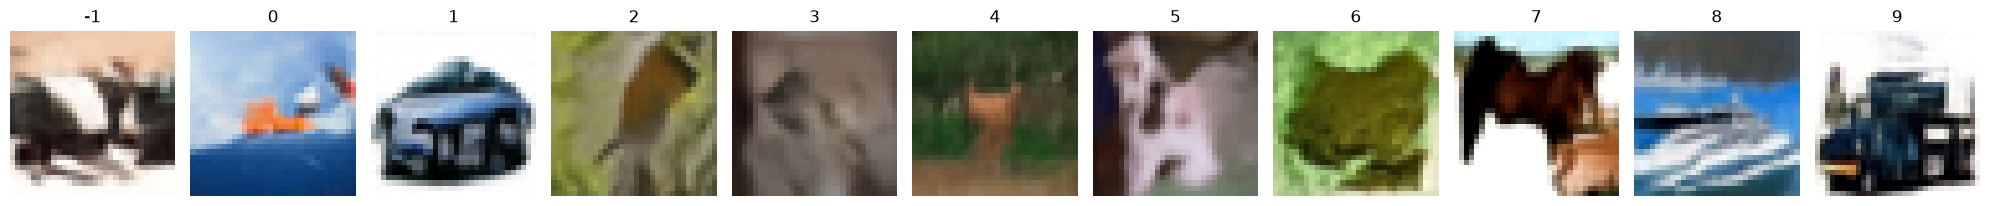

Epoch 56/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0736 - val_loss: 0.0314 - val_noise_loss: 0.0314 - learning_rate: 4.0631e-04
Steps: 100/100


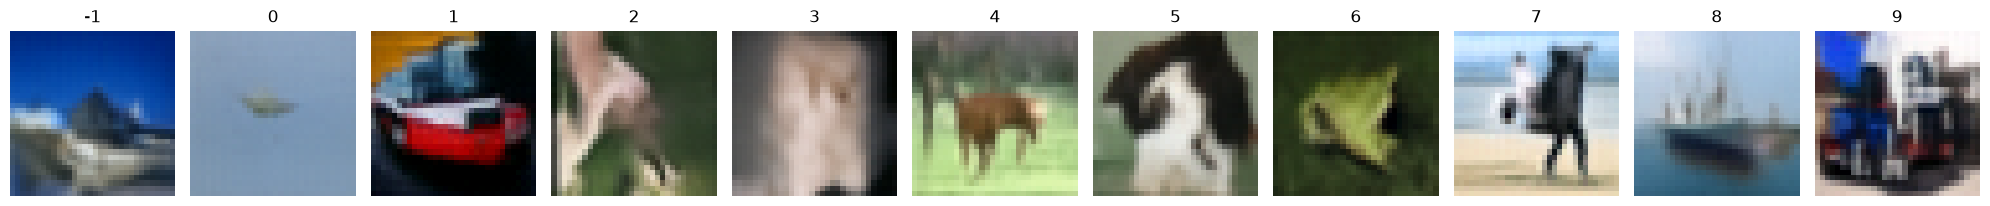

Epoch 57/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0735 - val_loss: 0.0310 - val_noise_loss: 0.0310 - learning_rate: 3.9093e-04
Steps: 100/100


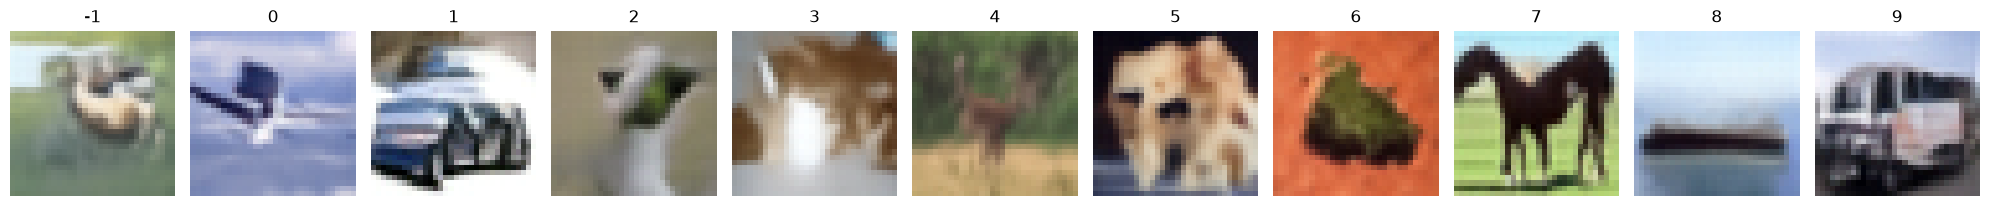

Epoch 58/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0289 - val_image_loss: 0.0699 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 3.7566e-04
Steps: 100/100


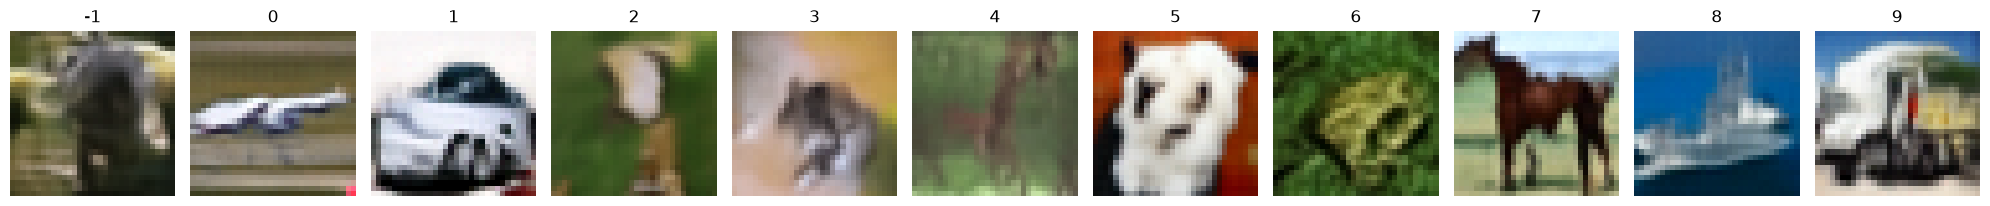

Epoch 59/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0704 - val_loss: 0.0304 - val_noise_loss: 0.0304 - learning_rate: 3.6050e-04
Steps: 100/100


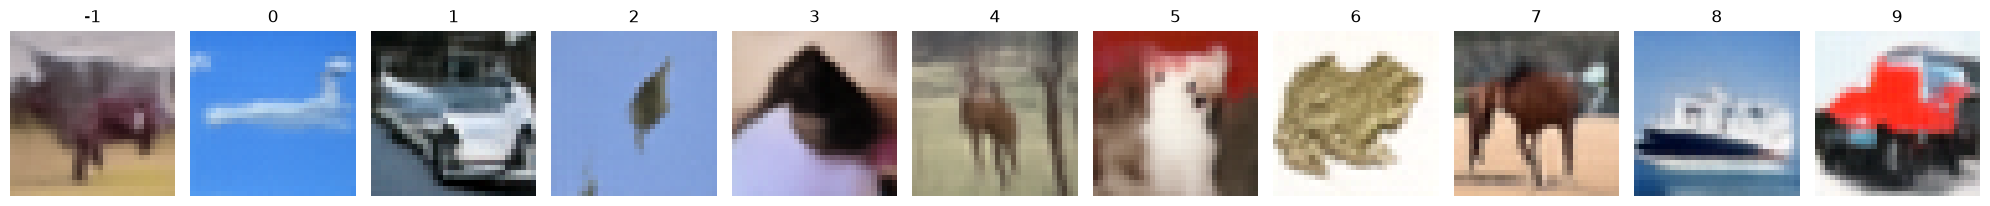

Epoch 60/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0291 - val_image_loss: 0.0706 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 3.4549e-04
Steps: 100/100


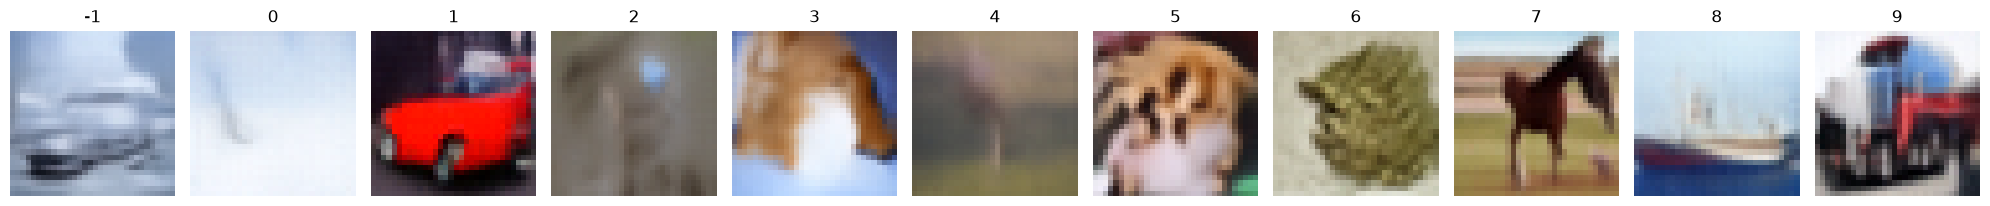

Epoch 61/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0293 - val_image_loss: 0.0712 - val_loss: 0.0304 - val_noise_loss: 0.0304 - learning_rate: 3.3063e-04
Steps: 100/100


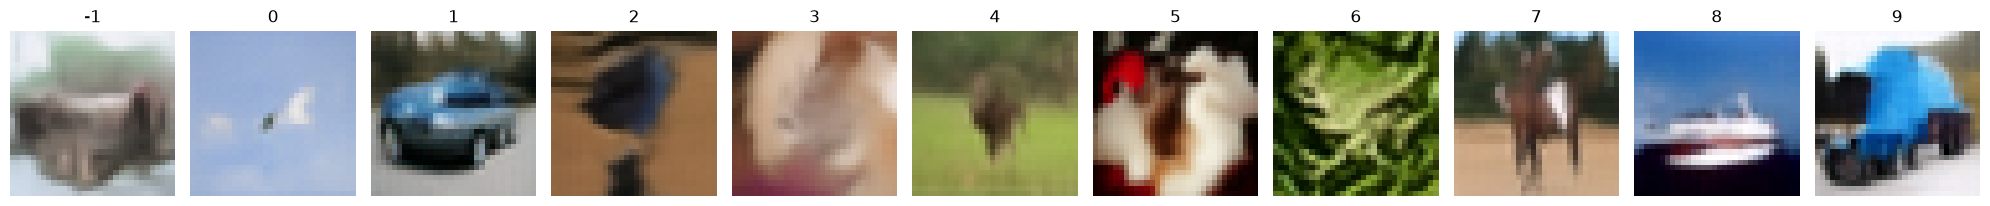

Epoch 62/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0290 - val_image_loss: 0.0722 - val_loss: 0.0318 - val_noise_loss: 0.0318 - learning_rate: 3.1594e-04
Steps: 100/100


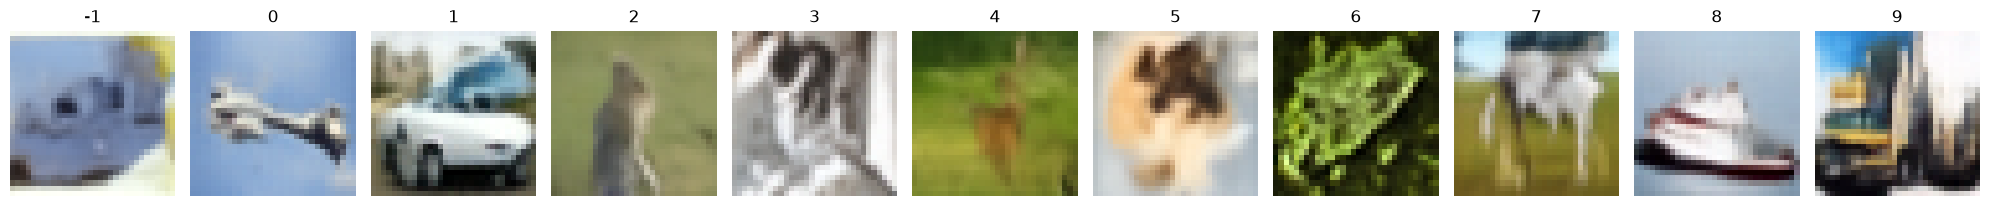

Epoch 63/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0289 - val_image_loss: 0.0728 - val_loss: 0.0306 - val_noise_loss: 0.0306 - learning_rate: 3.0143e-04
Steps: 100/100


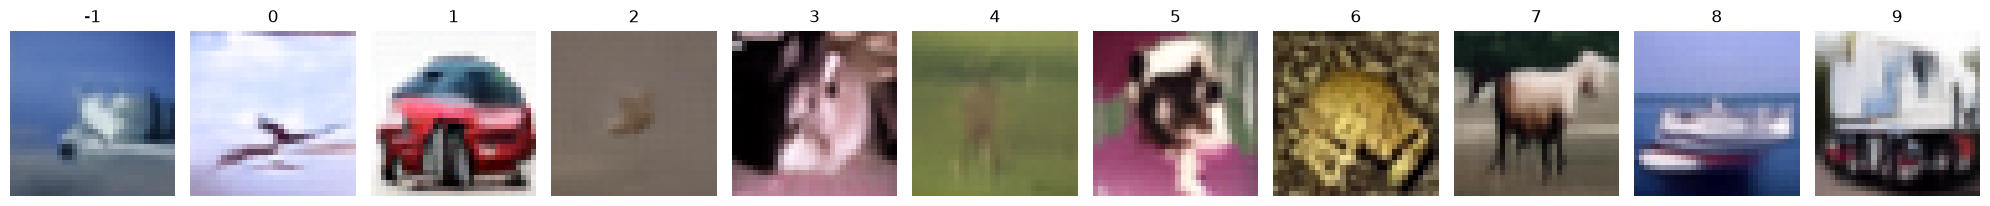

Epoch 64/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0292 - val_image_loss: 0.0732 - val_loss: 0.0305 - val_noise_loss: 0.0305 - learning_rate: 2.8711e-04
Steps: 100/100


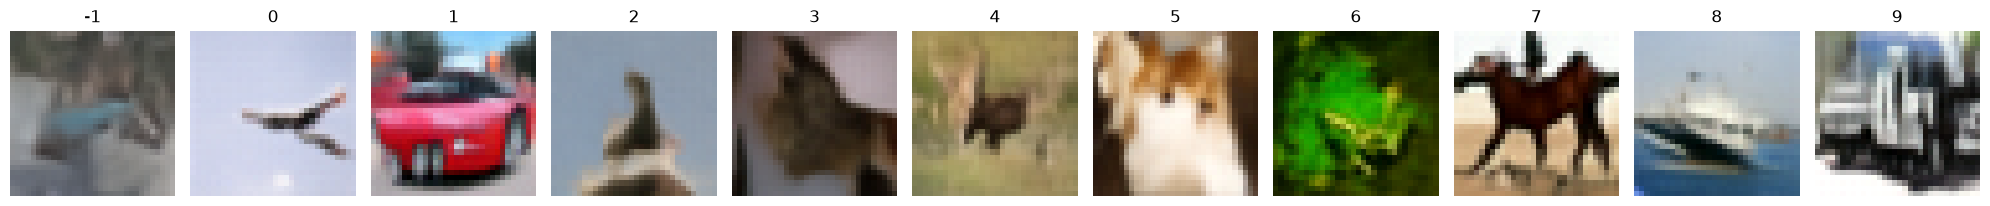

Epoch 65/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0696 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 2.7300e-04
Steps: 100/100


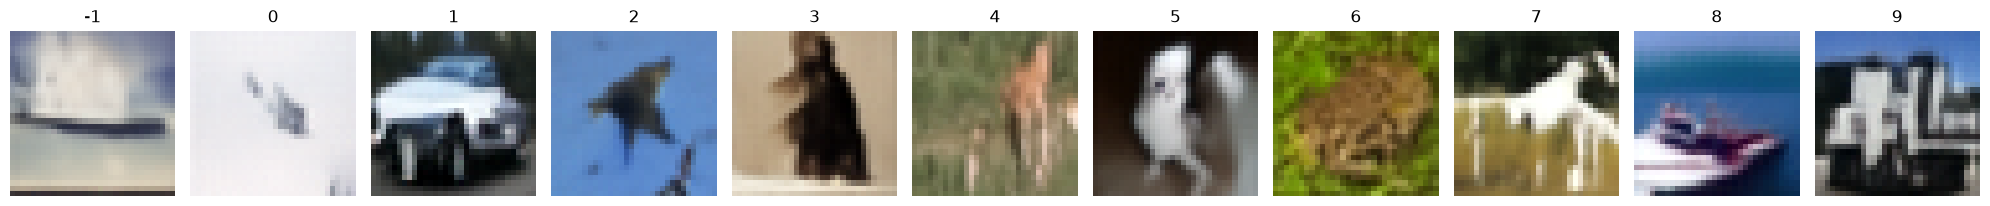

Epoch 66/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0287 - val_image_loss: 0.0695 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 2.5912e-04
Steps: 100/100


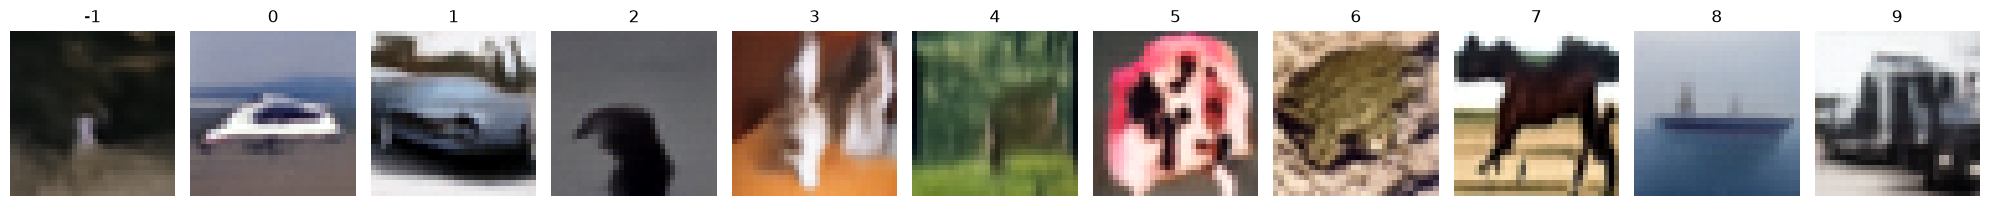

Epoch 67/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0700 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 2.4548e-04
Steps: 100/100


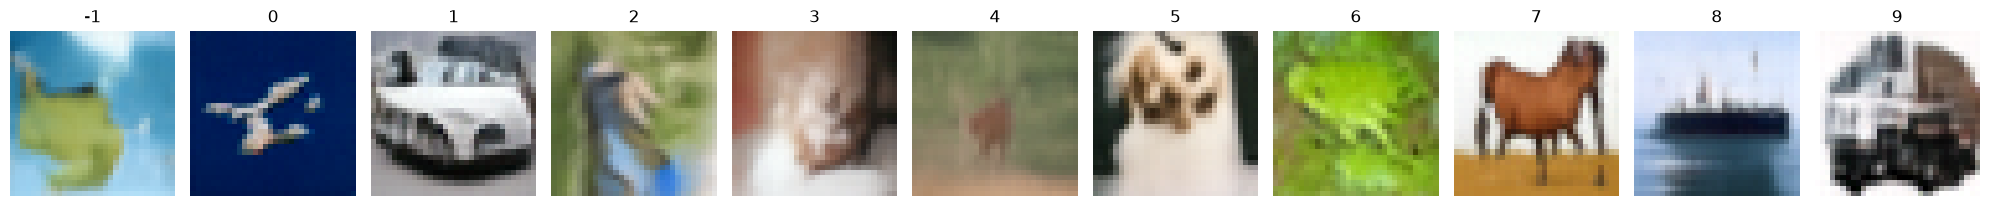

Epoch 68/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0709 - val_loss: 0.0304 - val_noise_loss: 0.0304 - learning_rate: 2.3209e-04
Steps: 100/100


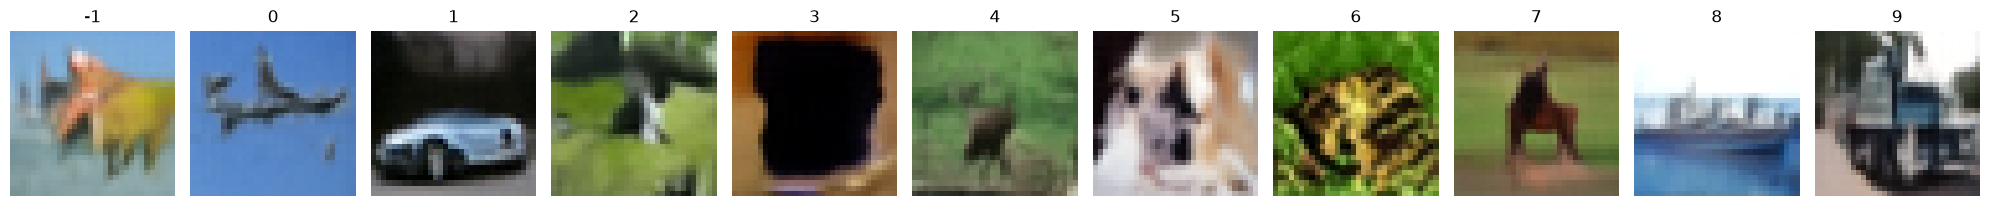

Epoch 69/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0290 - val_image_loss: 0.0709 - val_loss: 0.0303 - val_noise_loss: 0.0303 - learning_rate: 2.1896e-04
Steps: 100/100


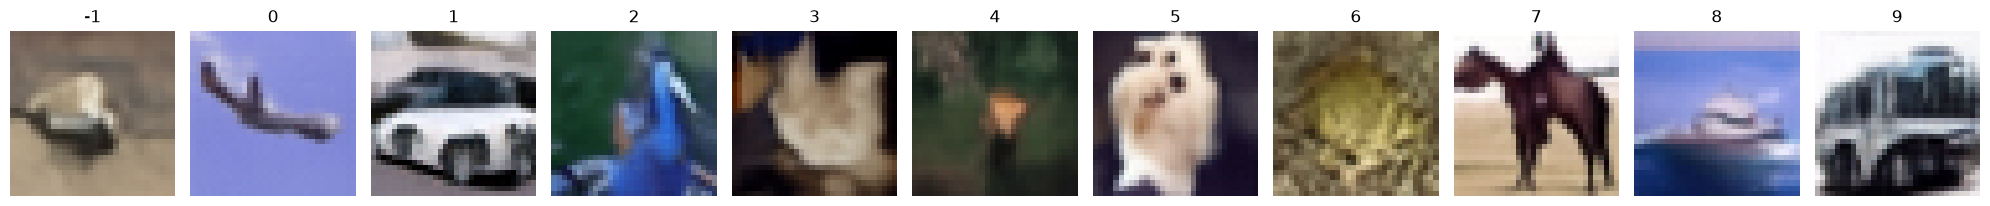

Epoch 70/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0701 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 2.0611e-04
Steps: 100/100


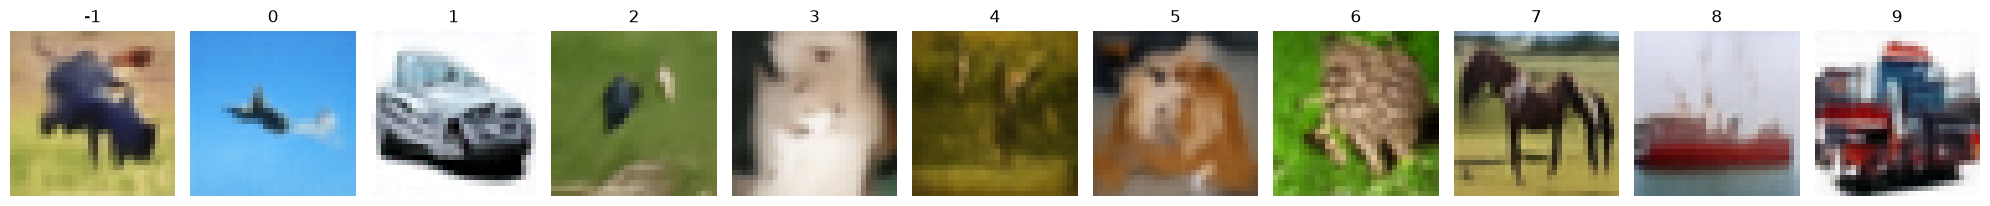

Epoch 71/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0287 - val_image_loss: 0.0706 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 1.9355e-04
Steps: 100/100


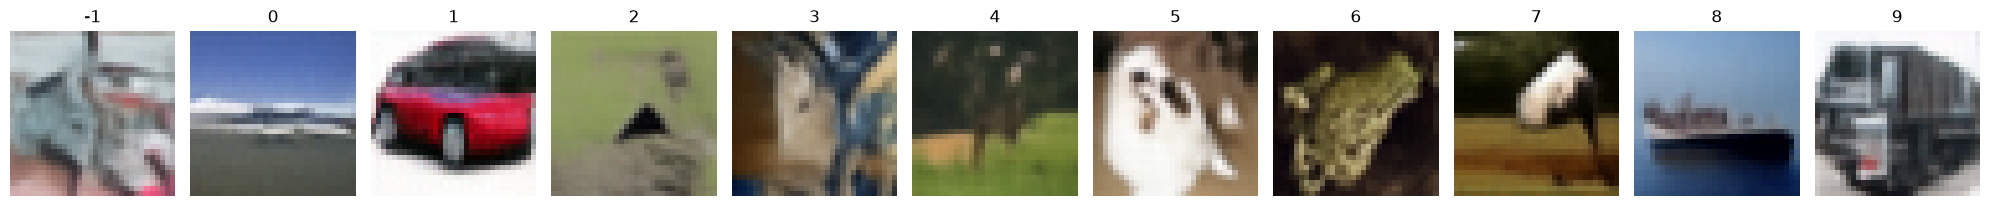

Epoch 72/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - noise_loss: 0.0286 - val_image_loss: 0.0698 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 1.8129e-04
Steps: 100/100


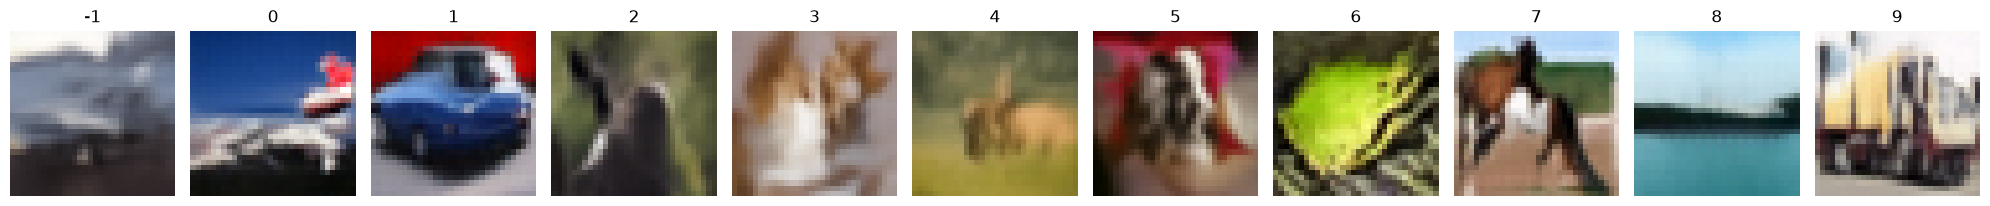

Epoch 73/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - noise_loss: 0.0288 - val_image_loss: 0.0707 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 1.6934e-04
Steps: 100/100


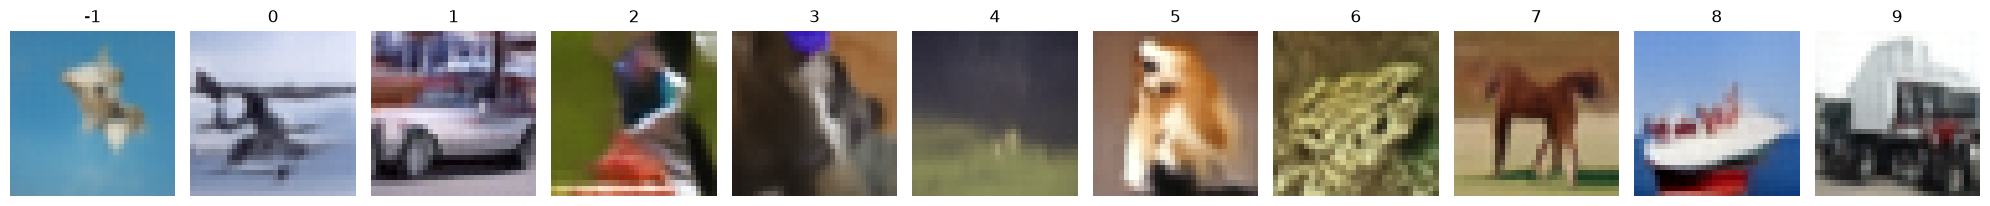

Epoch 74/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0695 - val_loss: 0.0299 - val_noise_loss: 0.0299 - learning_rate: 1.5773e-04
Steps: 100/100


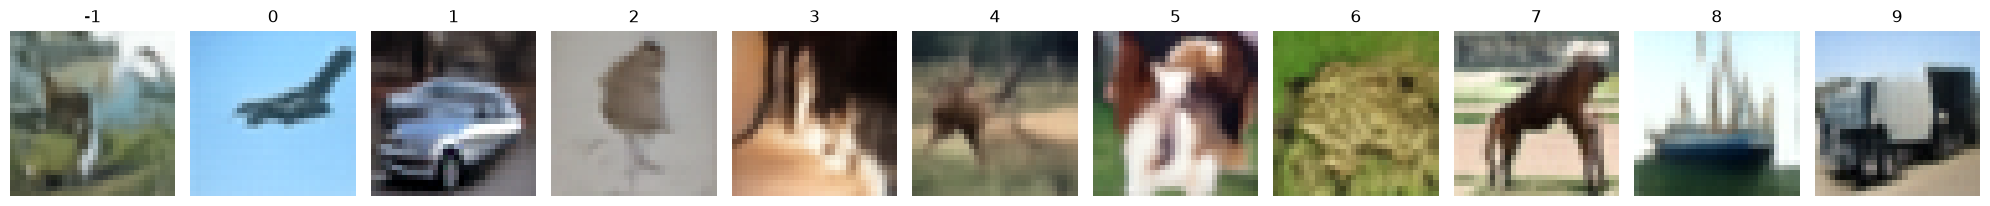

Epoch 75/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0289 - val_image_loss: 0.0686 - val_loss: 0.0317 - val_noise_loss: 0.0317 - learning_rate: 1.4645e-04
Steps: 100/100


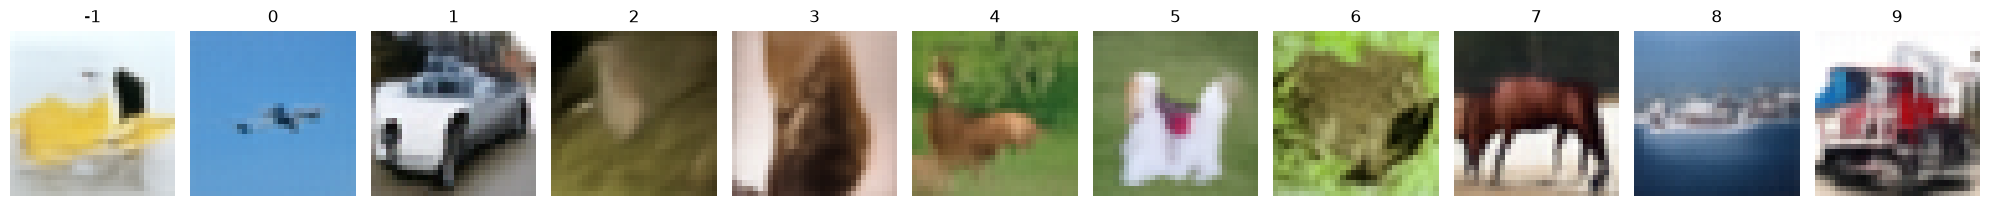

Epoch 76/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0701 - val_loss: 0.0312 - val_noise_loss: 0.0312 - learning_rate: 1.3552e-04
Steps: 100/100


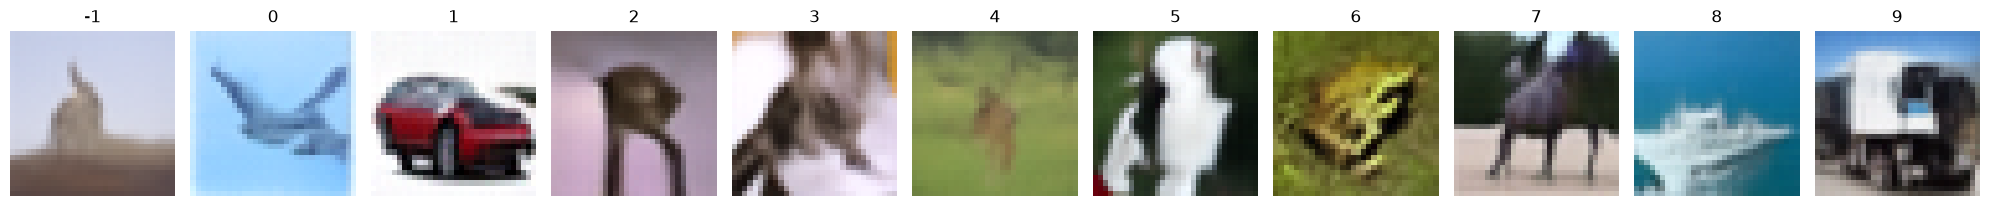

Epoch 77/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0693 - val_loss: 0.0303 - val_noise_loss: 0.0303 - learning_rate: 1.2494e-04
Steps: 100/100


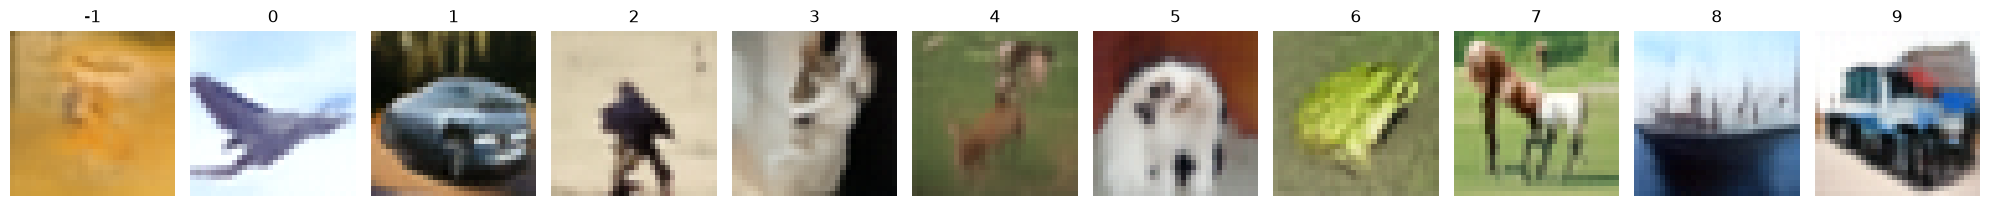

Epoch 78/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0688 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 1.1474e-04
Steps: 100/100


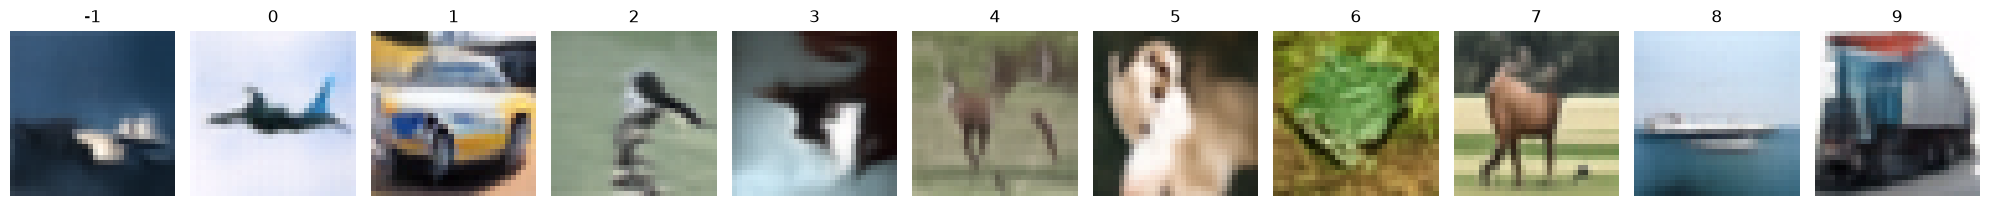

Epoch 79/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0697 - val_loss: 0.0313 - val_noise_loss: 0.0313 - learning_rate: 1.0492e-04
Steps: 100/100


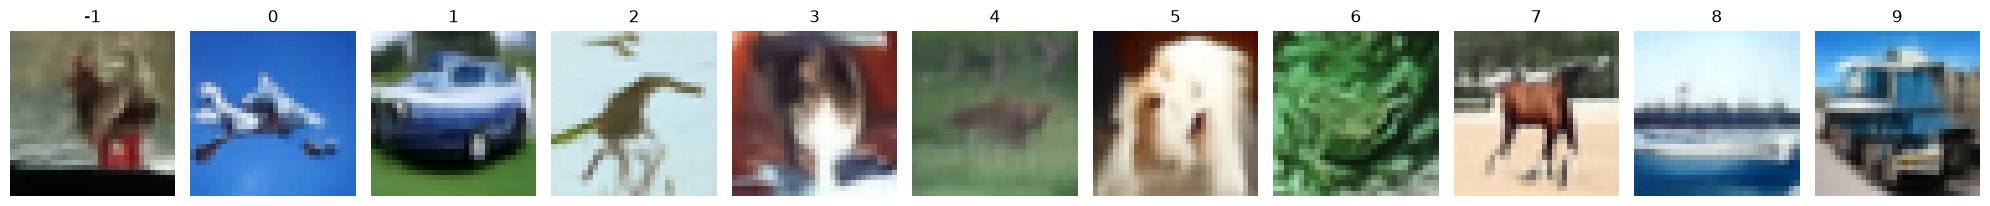

Epoch 80/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0290 - val_image_loss: 0.0696 - val_loss: 0.0303 - val_noise_loss: 0.0303 - learning_rate: 9.5491e-05
Steps: 100/100


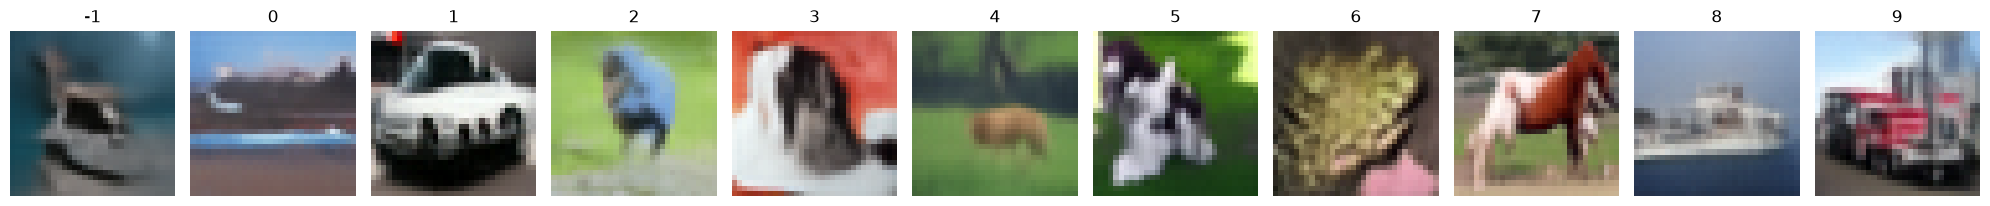

Epoch 81/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0284 - val_image_loss: 0.0711 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 8.6460e-05
Steps: 100/100


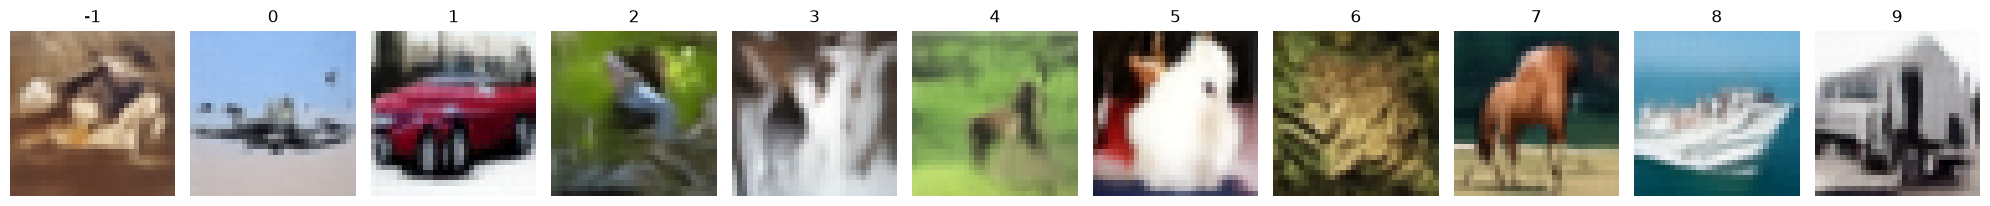

Epoch 82/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - noise_loss: 0.0287 - val_image_loss: 0.0693 - val_loss: 0.0310 - val_noise_loss: 0.0310 - learning_rate: 7.7836e-05
Steps: 100/100


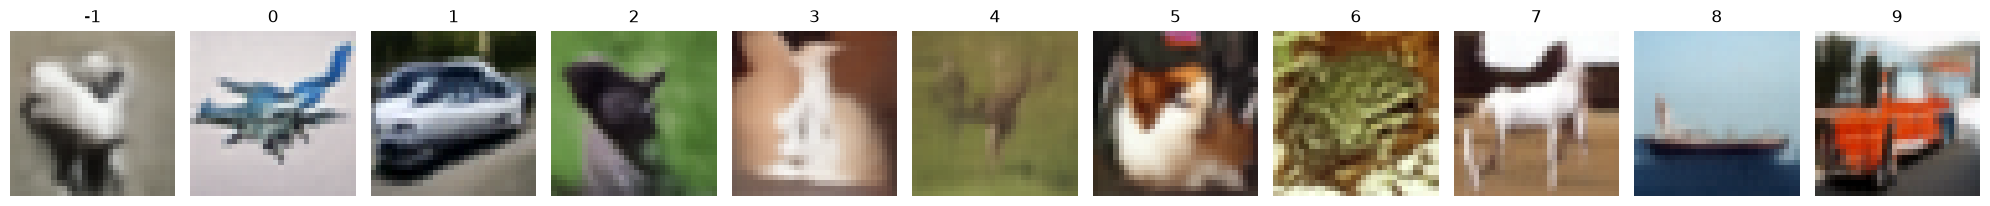

Epoch 83/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0292 - val_image_loss: 0.0697 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 6.9629e-05
Steps: 100/100


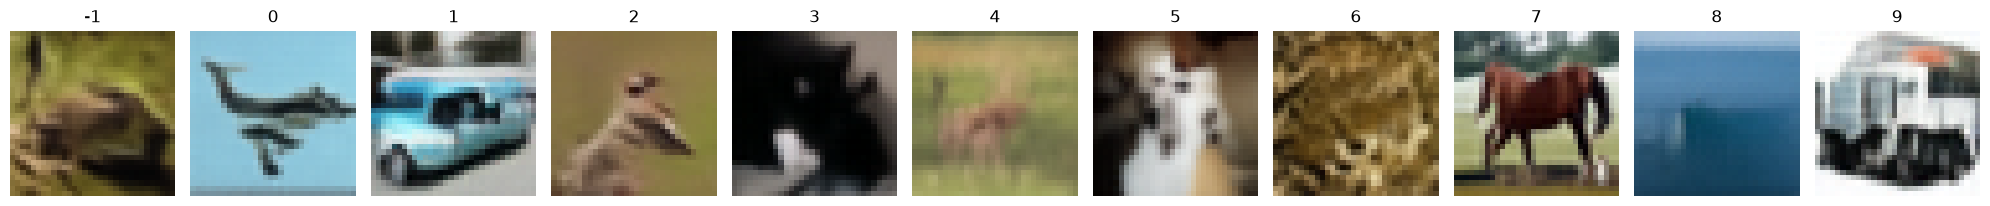

Epoch 84/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0694 - val_loss: 0.0305 - val_noise_loss: 0.0305 - learning_rate: 6.1847e-05
Steps: 100/100


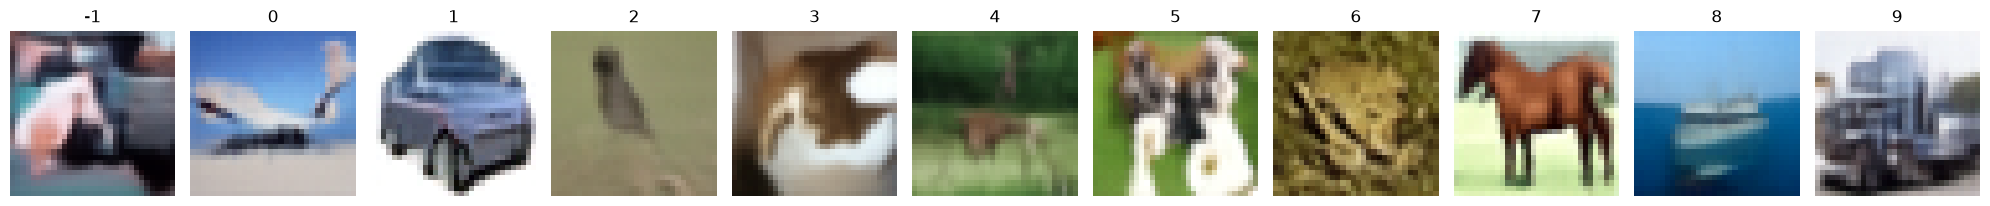

Epoch 85/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0706 - val_loss: 0.0306 - val_noise_loss: 0.0306 - learning_rate: 5.4497e-05
Steps: 100/100


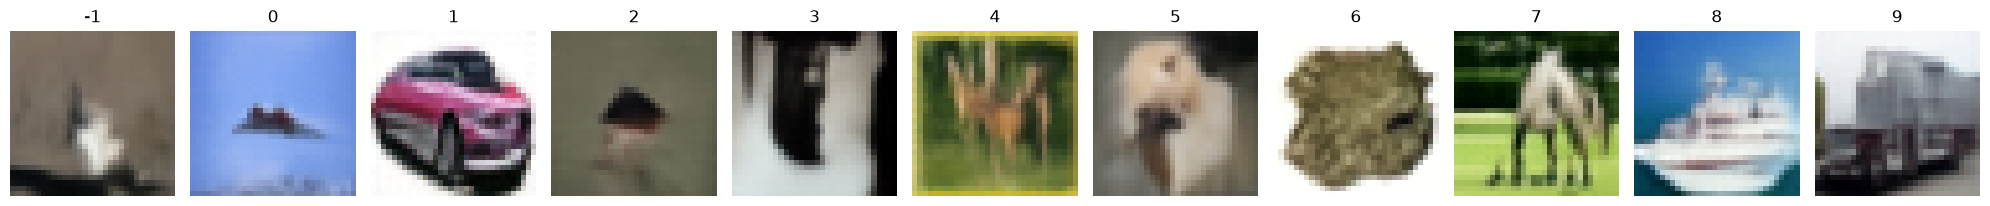

Epoch 86/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0686 - val_loss: 0.0308 - val_noise_loss: 0.0308 - learning_rate: 4.7586e-05
Steps: 100/100


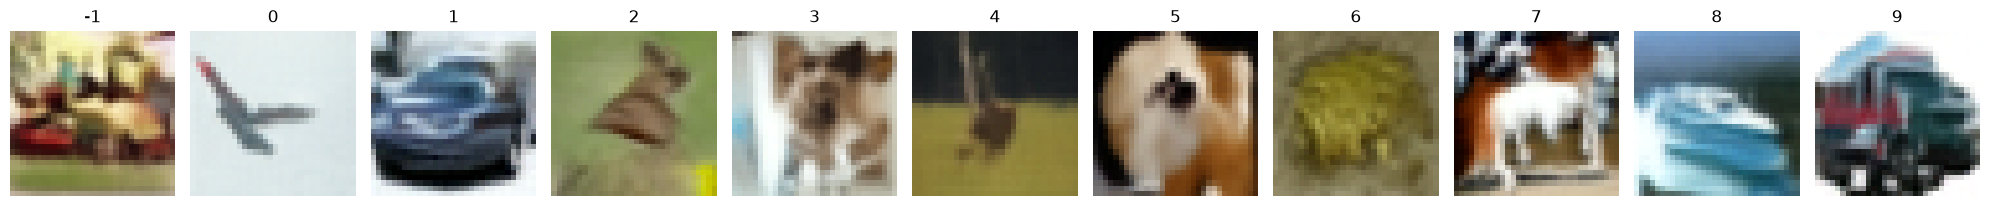

Epoch 87/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0284 - val_image_loss: 0.0713 - val_loss: 0.0299 - val_noise_loss: 0.0299 - learning_rate: 4.1123e-05
Steps: 100/100


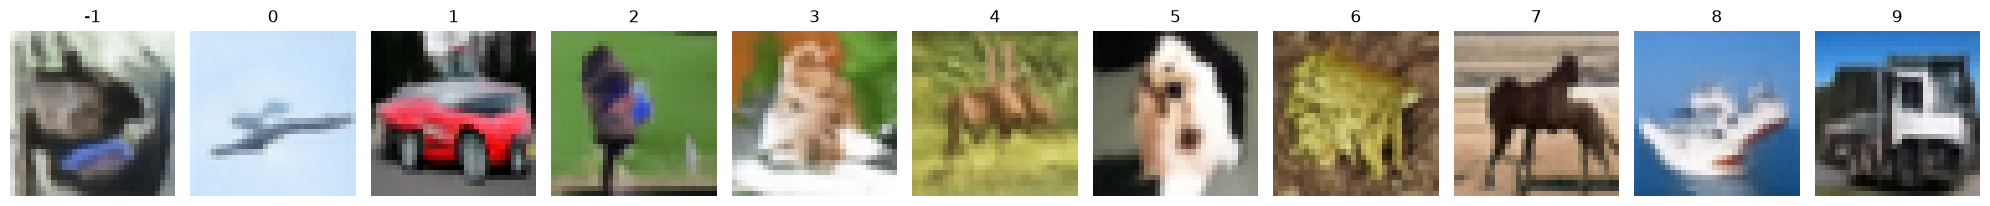

Epoch 88/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0692 - val_loss: 0.0304 - val_noise_loss: 0.0304 - learning_rate: 3.5112e-05
Steps: 100/100


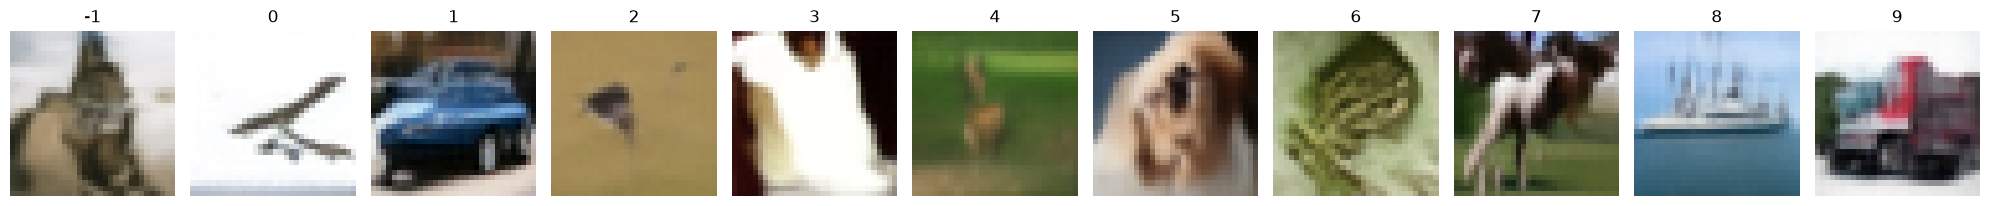

Epoch 89/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0697 - val_loss: 0.0310 - val_noise_loss: 0.0310 - learning_rate: 2.9560e-05
Steps: 100/100


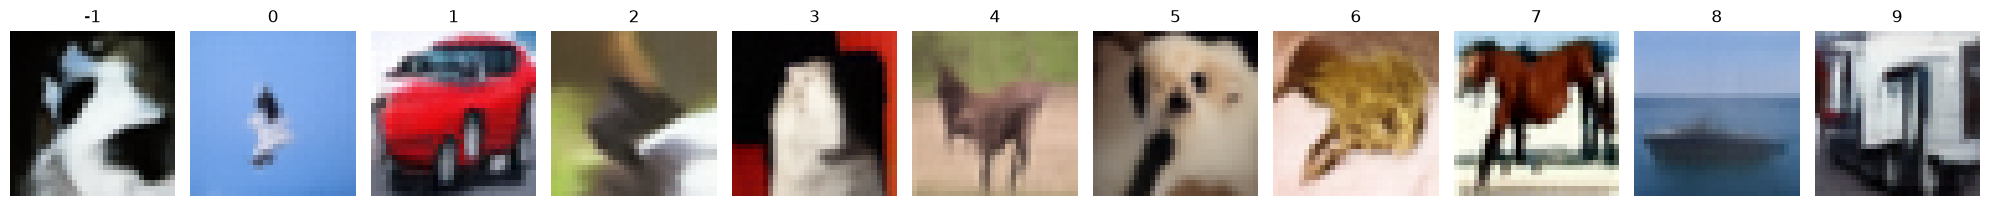

Epoch 90/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0697 - val_loss: 0.0303 - val_noise_loss: 0.0303 - learning_rate: 2.4472e-05
Steps: 100/100


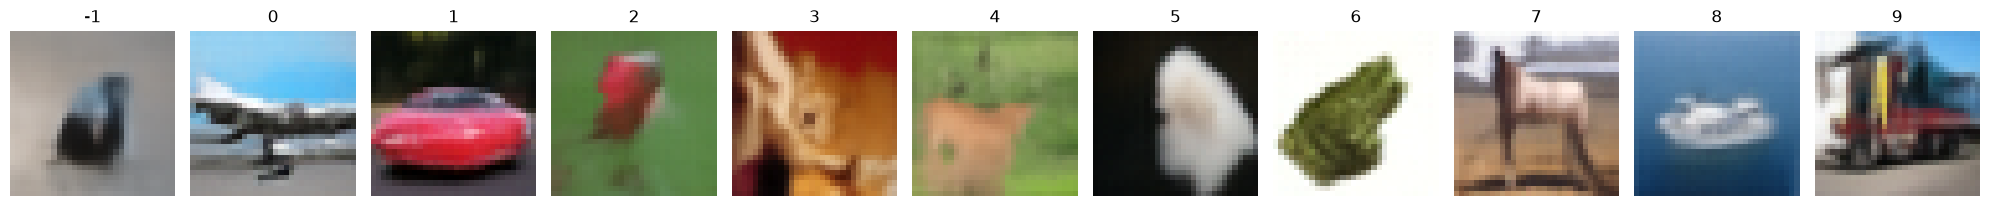

Epoch 91/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0683 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 1.9853e-05
Steps: 100/100


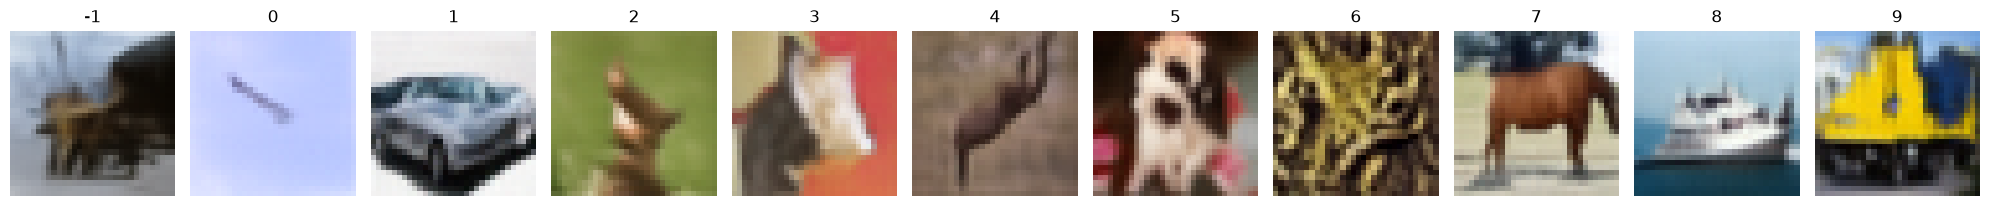

Epoch 92/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0693 - val_loss: 0.0309 - val_noise_loss: 0.0309 - learning_rate: 1.5708e-05
Steps: 100/100


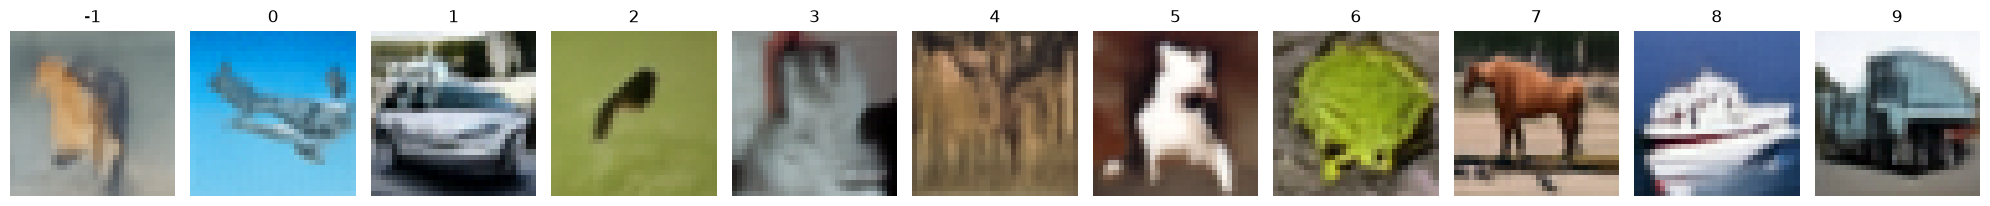

Epoch 93/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0693 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 1.2042e-05
Steps: 100/100


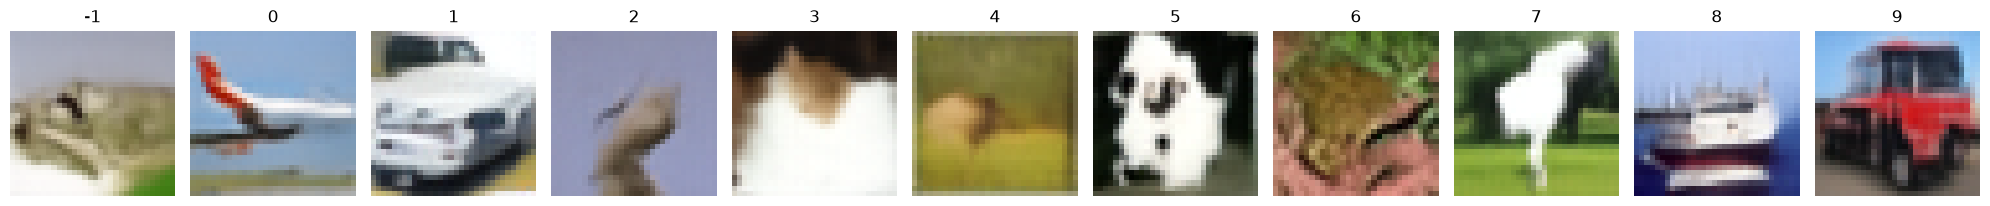

Epoch 94/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0694 - val_loss: 0.0311 - val_noise_loss: 0.0311 - learning_rate: 8.8564e-06
Steps: 100/100


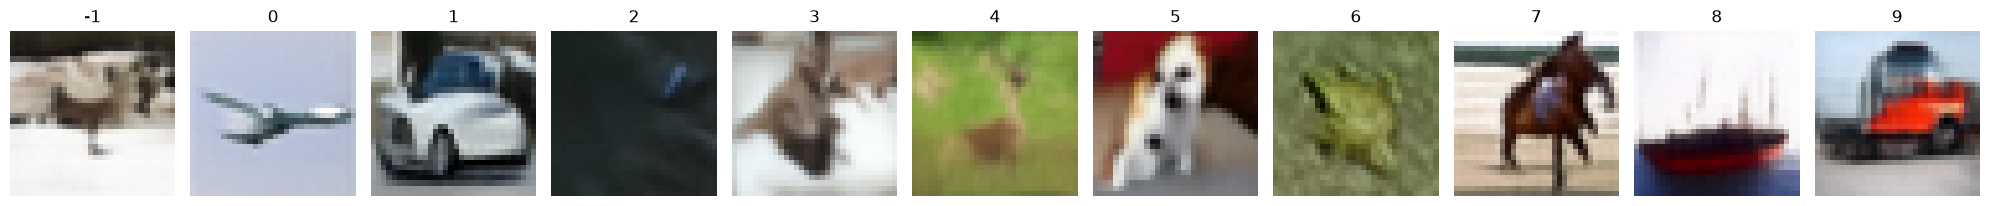

Epoch 95/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0287 - val_image_loss: 0.0696 - val_loss: 0.0306 - val_noise_loss: 0.0306 - learning_rate: 6.1558e-06
Steps: 100/100


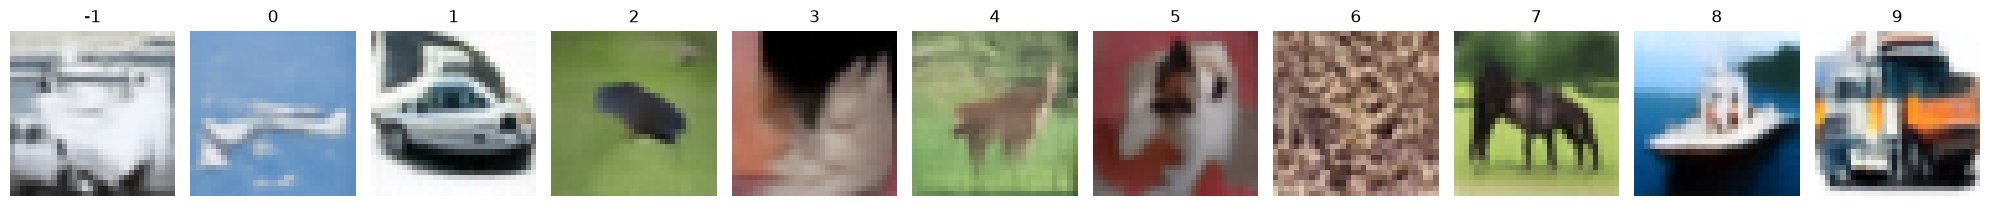

Epoch 96/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0691 - val_loss: 0.0306 - val_noise_loss: 0.0306 - learning_rate: 3.9426e-06
Steps: 100/100


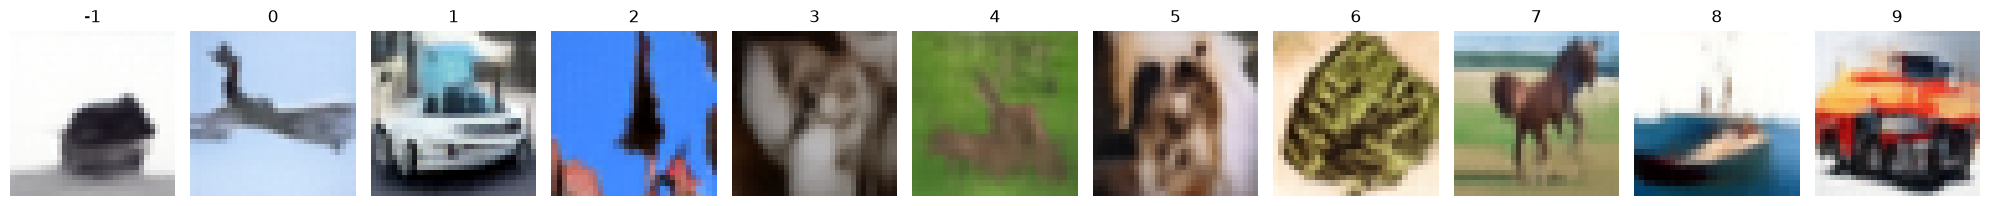

Epoch 97/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0285 - val_image_loss: 0.0707 - val_loss: 0.0306 - val_noise_loss: 0.0306 - learning_rate: 2.2190e-06
Steps: 100/100


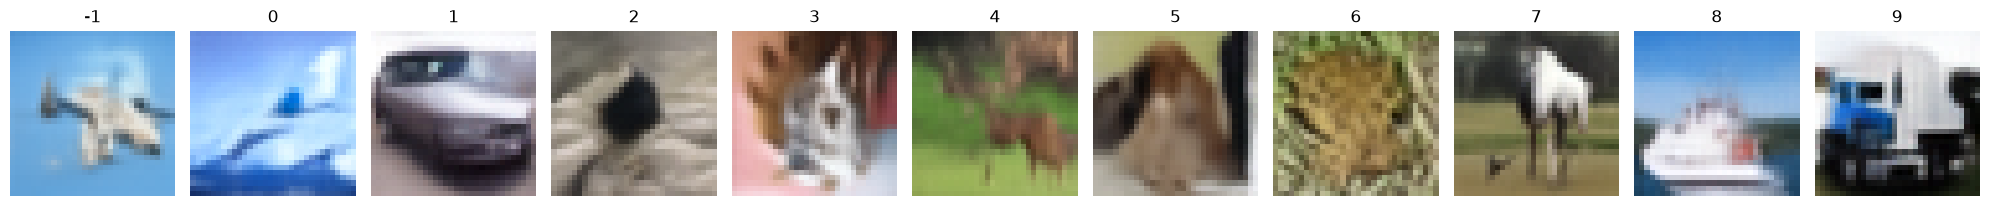

Epoch 98/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0288 - val_image_loss: 0.0679 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 9.8664e-07
Steps: 100/100


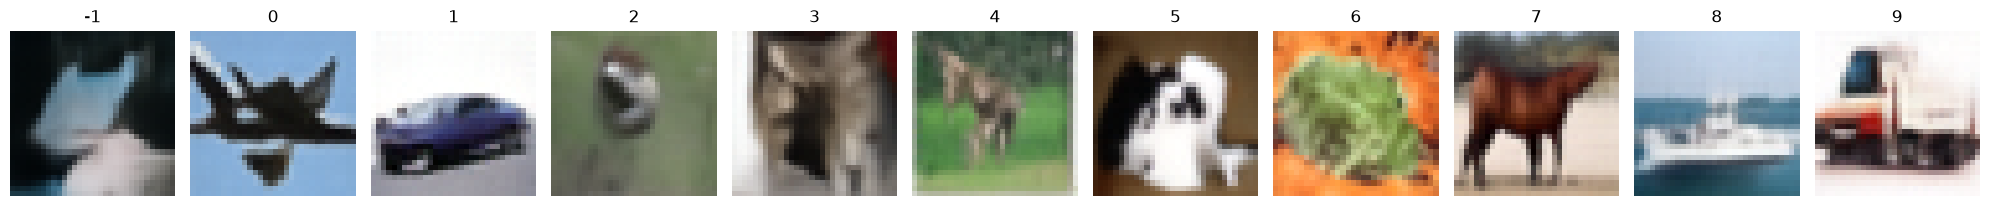

Epoch 99/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0286 - val_image_loss: 0.0696 - val_loss: 0.0307 - val_noise_loss: 0.0307 - learning_rate: 2.4673e-07
Steps: 100/100


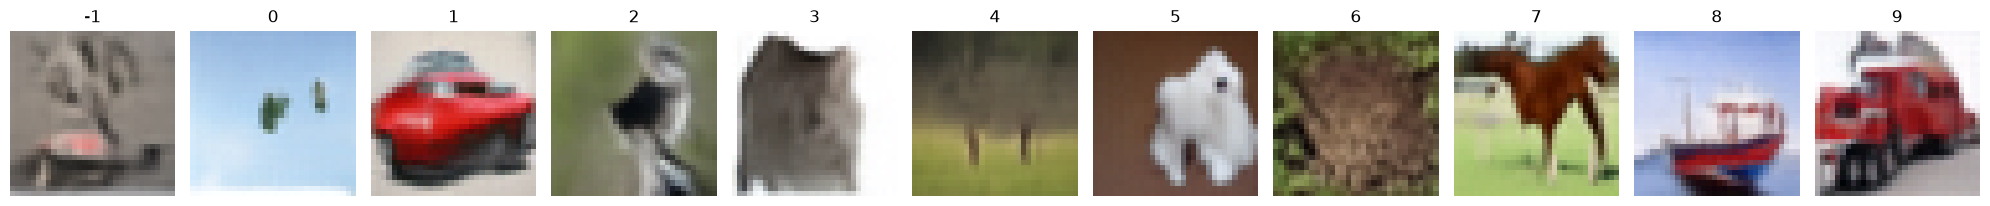

Epoch 100/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 0.0283 - val_image_loss: 0.0683 - val_loss: 0.0304 - val_noise_loss: 0.0304 - learning_rate: 0.0000e+00
Steps: 100/100


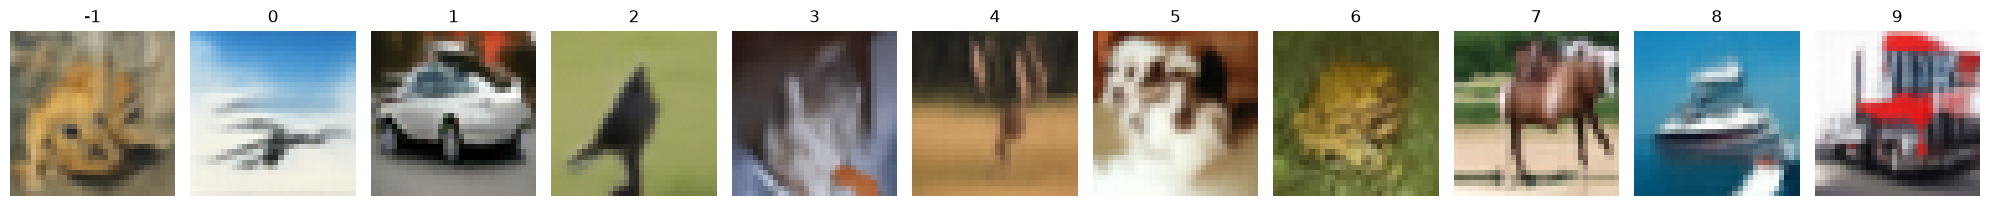

In [8]:
history_generator = model.fit_generator(
    x=trainset, 
    epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list
).history

## Classifier training


In [9]:
history_classifier = model.fit_discriminator(
    x=trainset, 
    epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list[:-1]
).history

history = model.merge_result_dicts((
    history_generator, 
    history_classifier
))

Epoch 1/100


2026-10-12 23:40:25.635253: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17893', 100 bytes spill stores, 100 bytes spill loads

2026-10-12 23:40:26.916596: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_345', 1144 bytes spill stores, 1144 bytes spill loads

2026-10-12 23:40:27.070906: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18158', 96 bytes spill stores, 96 bytes spill loads

2026-10-12 23:40:27.077292: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_17893', 576 bytes spill stores, 576 bytes spill loads

2026-10-12 23:40:32.465508: I 

390/390 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - classifier_accuracy: 0.2896 - classifier_loss: 2.9037

2026-10-12 23:42:07.497714: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_65', 4 bytes spill stores, 4 bytes spill loads

2026-10-12 23:42:07.861908: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_70', 8 bytes spill stores, 8 bytes spill loads

2026-10-12 23:42:12.047766: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_70', 304 bytes spill stores, 304 bytes spill loads

2026-10-12 23:42:24.311656: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by us

390/390 ━━━━━━━━━━━━━━━━━━━━ 190s 183ms/step - classifier_accuracy: 0.3947 - classifier_loss: 2.0318 - val_classifier_accuracy: 0.1338 - val_classifier_loss: 3.4876 - learning_rate: 9.9975e-04
Epoch 2/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - classifier_accuracy: 0.5802 - classifier_loss: 1.1918 - val_classifier_accuracy: 0.2277 - val_classifier_loss: 2.1392 - learning_rate: 9.9901e-04
Epoch 3/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - classifier_accuracy: 0.6343 - classifier_loss: 1.0383 - val_classifier_accuracy: 0.2411 - val_classifier_loss: 2.1349 - learning_rate: 9.9778e-04
Epoch 4/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - classifier_accuracy: 0.6646 - classifier_loss: 0.9554 - val_classifier_accuracy: 0.3645 - val_classifier_loss: 1.7116 - learning_rate: 9.9606e-04
Epoch 5/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - classifier_accuracy: 0.6838 - classifier_loss: 0.8978 - val_classifier_accuracy: 0.4530 - val_classifier_loss: 1.5014 - learning_rate: 9.9384

## Save weights


In [10]:
model.save_weights("./files/models/CIFAR10 DiT CLFV2/model.weights.h5")

## Evaluate EMA and raw networks


In [11]:
model.evaluate(x=valset, eval_both=True, network_name="ema")

79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - image_loss: 0.0694 - loss: 0.0308 - noise_loss: 0.0308
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - classifier_accuracy: 0.7905 - classifier_loss: 0.7161


{'loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.030842173844575882>,
 'noise_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.030842173844575882>,
 'image_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.0693538635969162>,
 'classifier_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.7161413431167603>,
 'classifier_accuracy': <tf.Tensor: shape=(), dtype=float32, numpy=0.7905000448226929>}

In [12]:
model.evaluate(x=valset, eval_both=True, network_name="raw")

79/79 ━━━━━━━━━━━━━━━━━━━━ 19s 123ms/step - image_loss: 0.0686 - loss: 0.0307 - noise_loss: 0.0307
79/79 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - classifier_accuracy: 0.7905 - classifier_loss: 0.7161


{'loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.030741587281227112>,
 'noise_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.030741587281227112>,
 'image_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.0686430111527443>,
 'classifier_loss': <tf.Tensor: shape=(), dtype=float32, numpy=0.7161413431167603>,
 'classifier_accuracy': <tf.Tensor: shape=(), dtype=float32, numpy=0.7905000448226929>}

In [13]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=256, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8377


2026-10-13 00:40:39.594868: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8377000093460083

In [14]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=256, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8319


2026-10-13 00:41:32.936187: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8319000005722046

In [15]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=4, 
    max_t=128, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8420


0.8420000076293945

In [16]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=128, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.8217


2026-10-13 00:52:38.186434: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.8216999769210815

In [17]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=64, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8485


0.8485000133514404

In [18]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=64, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.7902


0.7901999950408936

In [19]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=32, 
    t_range_drop_rate=0.75
)

Step (79/79) --- Ensemble Accuracy: 0.8465


0.8464999794960022

In [20]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=32, 
    t_range_drop_rate=0.99
)

Step (79/79) --- Ensemble Accuracy: 0.7902


2026-10-13 01:01:22.202058: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


0.7901999950408936

In [ ]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=16, 
    t_range_drop_rate=0.75
)

Step (67/79) --- Ensemble Accuracy: 0.8392

In [22]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=8
)

Step (79/79) --- Ensemble Accuracy: 0.8475


0.8475000262260437

In [30]:
model.evaluate_ensemble_accuracy(
    valset, 
    t_chunk_size=8, 
    max_t=4 
)

Step (79/79) --- Ensemble Accuracy: 0.8413


0.8413000106811523

## Class-conditional samples


Steps: 100/100


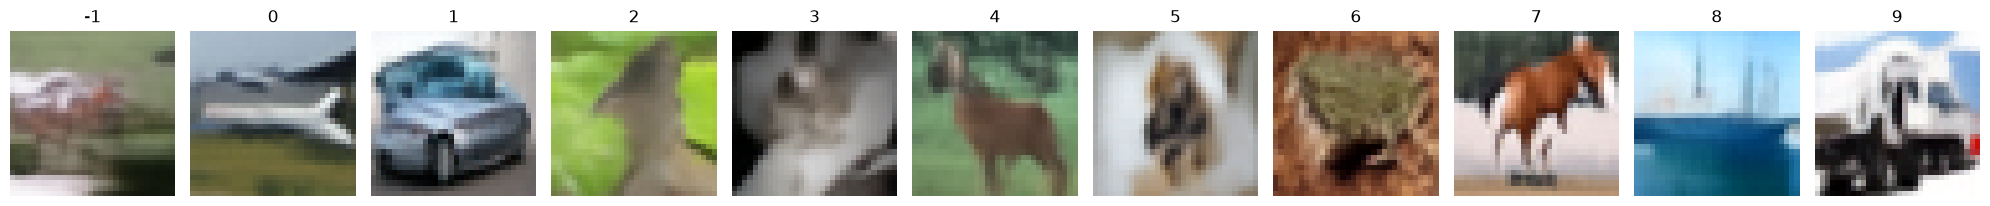

In [31]:
from common.utils import plot_images


imgs = model.sample(add_null_label=True, scale=3., eta=0., steps=100, verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 100/100


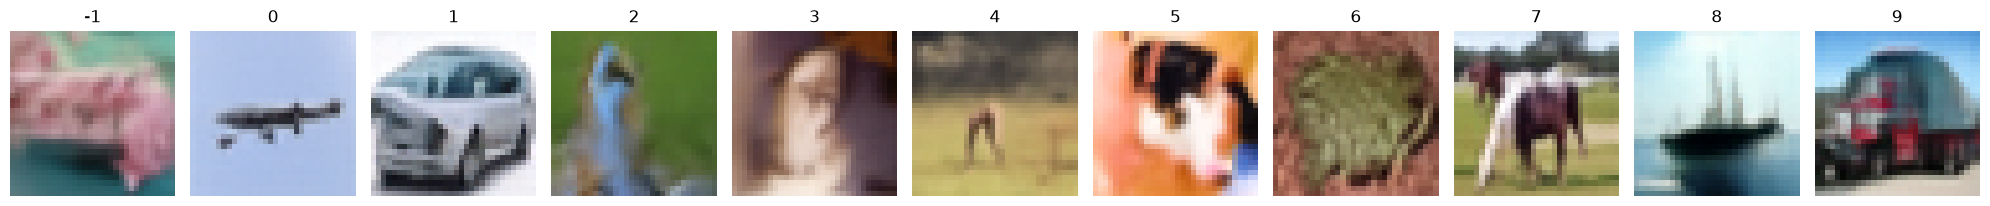

In [32]:
imgs = model.sample(add_null_label=True, scale=3., steps=100, verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 100/100


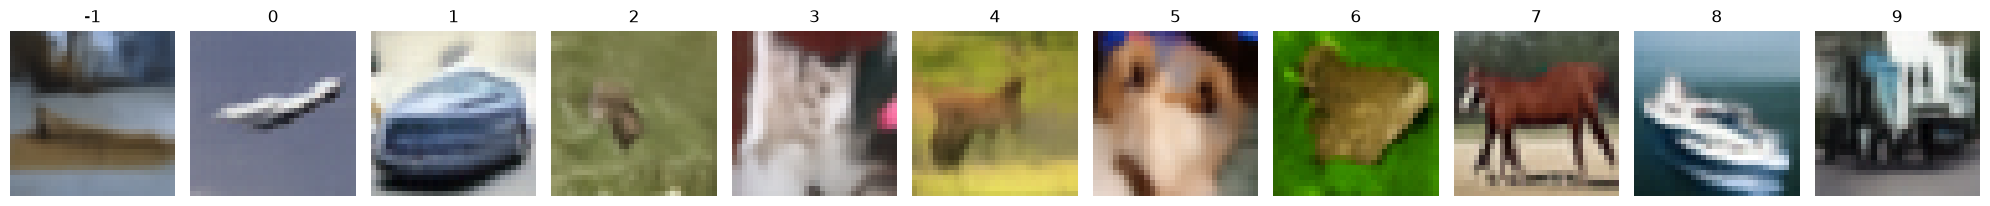

In [33]:
imgs = model.sample(add_null_label=True, scale=3., verbose=True)
plot_images(imgs, has_null_label=True)

Steps: 100/100


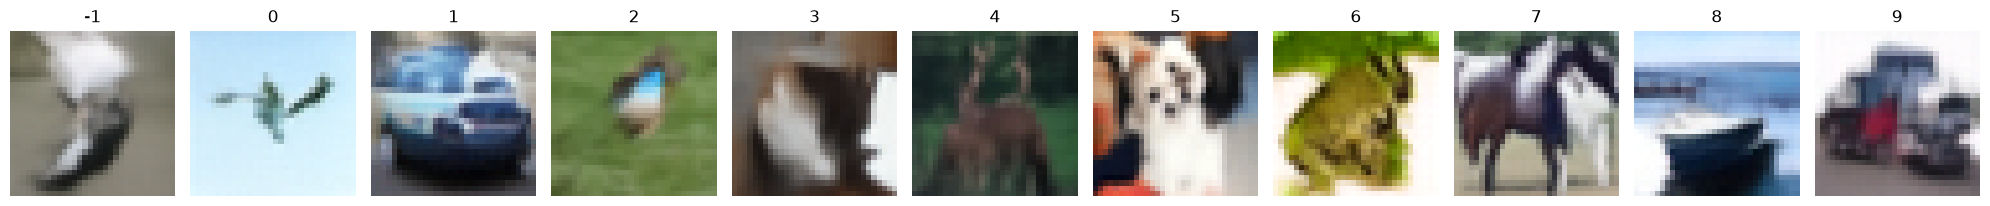

In [34]:
imgs = model.sample(add_null_label=True, scale=3., verbose=True)
plot_images(imgs, has_null_label=True)

## Training history


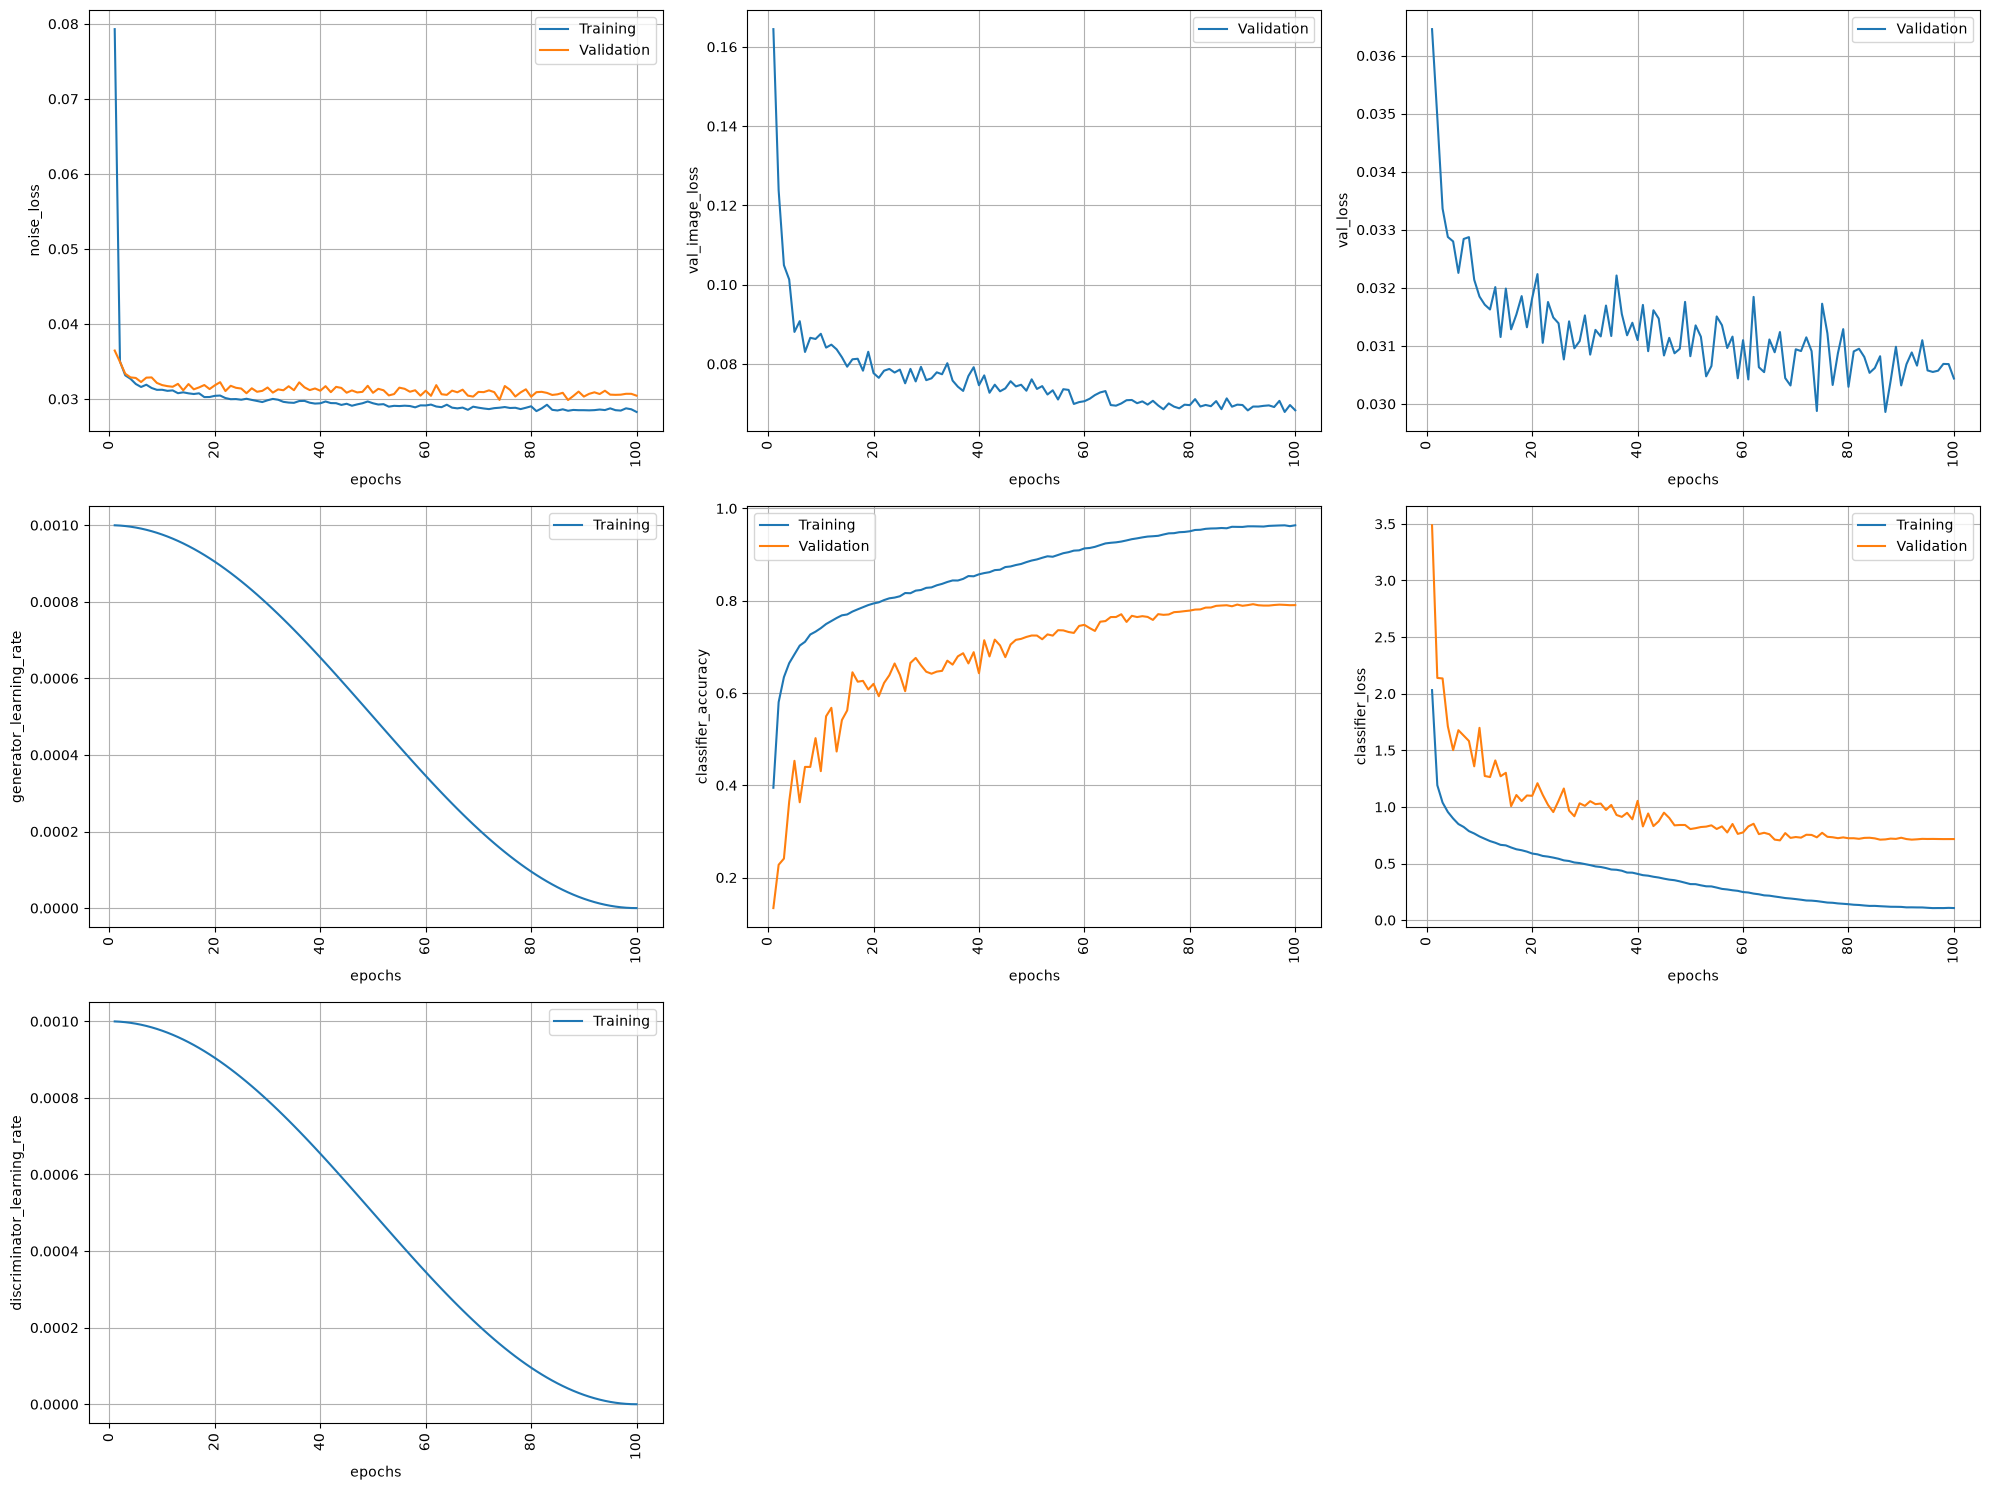

In [35]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

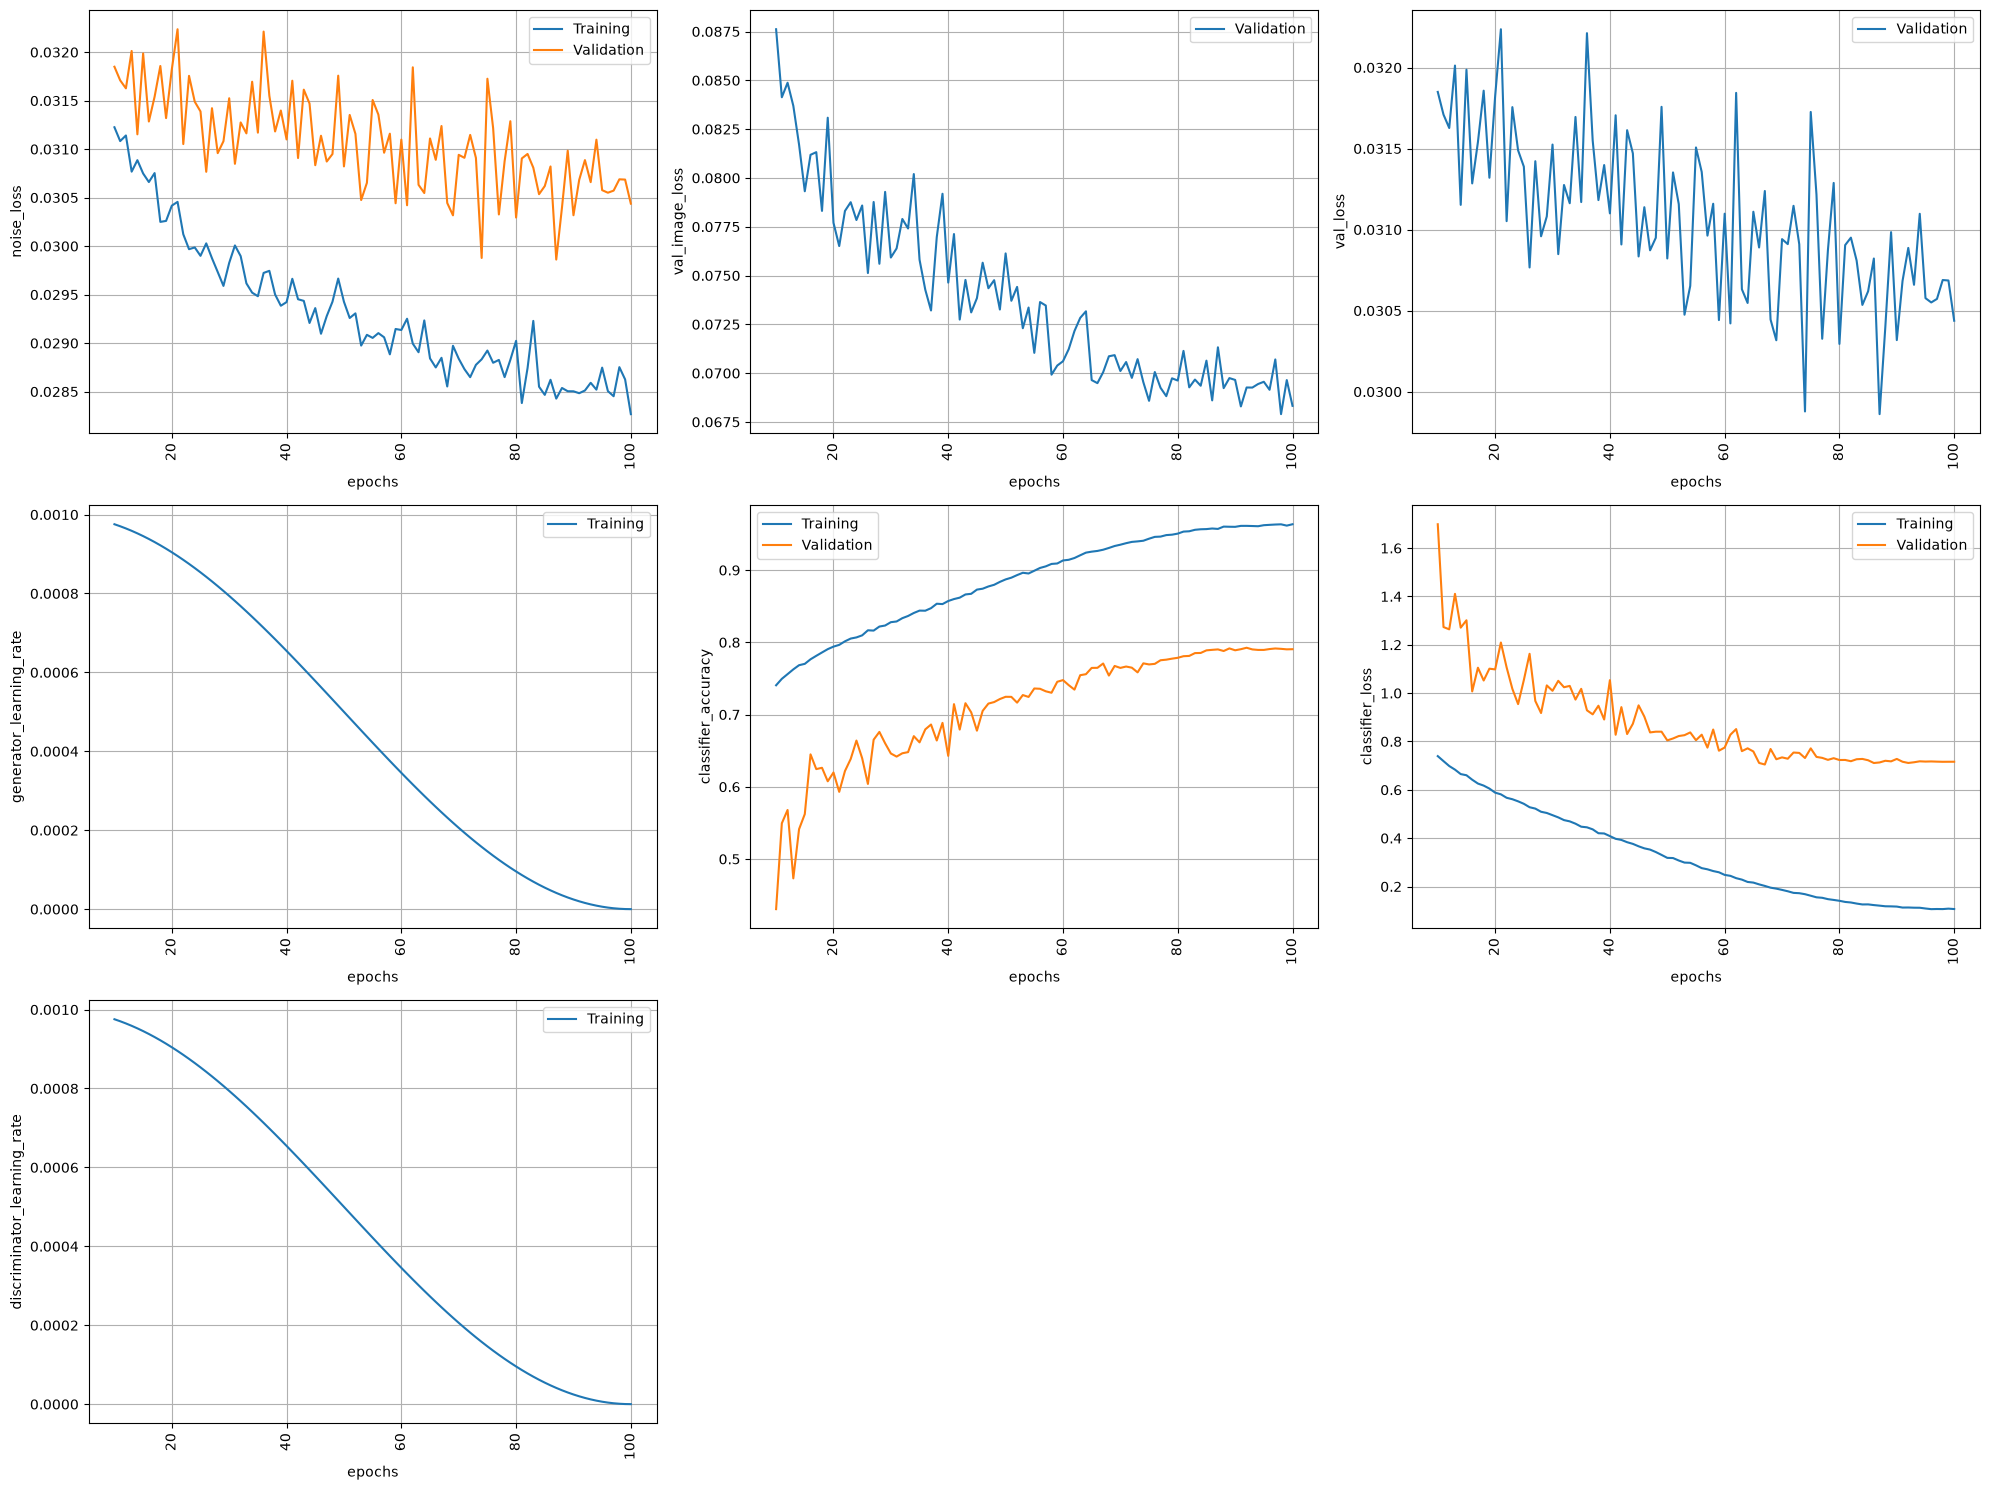

In [36]:
plot_history(history, show_all_x_ticks=False, range_=(9, None))